In [1]:
import numpy as np
import matplotlib.pyplot as pl
import matplotlib.animation as animation
import operator 
import sys
from scipy.signal import find_peaks
from scipy.stats import norm
from numpy.random import default_rng
#from scipy.fft import fft
from scipy.optimize import curve_fit
import matplotlib.cm as cm
np.random.seed = 1234

In [2]:
# Simulate Data

MHz1 = 121.67 # Nitrogen 

# Acquisition Parameters
# Spectral Window
SW1_ppm = 60
SW1_Hz = SW1_ppm*MHz1    #
# Carrier Setting
oNp_ppm = 115
oNp_Hz = oNp_ppm*MHz1    #

LL_ppm = oNp_ppm - SW1_ppm/2 #
HL_ppm = oNp_ppm + SW1_ppm/2 #
LL_Hz = LL_ppm*MHz1
HL_Hz = HL_ppm*MHz1

# Number of points and Acquisition time
N1 = 512
Delta_T1 = 1/(2*SW1_Hz)
T1 = N1*Delta_T1
FIDRES1 = 1/T1
num_spins = 8

# Relaxation Times
LW1 = np.random.uniform(low=0.1, high=1, size=(8,))  # Hz
R1 = np.pi * LW1 / N1
# Resonances (where peaks will appear)
#F1_ppm = np.random.uniform(low=110,high=120,size=(8,))
F1_ppm = np.array([111.484375, 112.0703125, 115.3515625, 115.9375, 116.2890625, 117.2265625, 117.4609375, 118.046875])
F1_Hz = F1_ppm * MHz1
# In terms of harmonics (pts)
F1_pts = (F1_Hz - LL_Hz) * (N1/SW1_Hz)
#R1_pts = R1 * Delta_T1 * N1

omega1 = 2 * np.pi * F1_pts#_int

# Normalized Intensities 
S1 = np.random.uniform(low=1.0, high=5.0, size=(8,))

# Sampled points (uniform sampling)
np1 = np.arange(0,N1)
np1_ZF = np.arange(0,2*N1)
t1 = np.linspace(0.0,T1,N1)

# Sampling matrix (resonances)
omega1E = omega1[:, None] * np1[None, :]
# Sampling matrix (relaxation)
R1E = R1[:, None] * np1[None, :]
ph = 0.3

# Uniformly Sampled FID, fully quadrature detected
st1_raw_spins = (np.exp(1j * omega1E/N1) * np.exp(-R1E) * S1[:, None])
st1_raw = st1_raw_spins.sum(0)

st1max = np.max(st1_raw.real)
st1min = np.min(st1_raw.real)
# standard deviation
FIDnoise_real = np.random.normal(0, st1max/50,N1)
FIDnoise_imag = np.random.normal(0,st1max/50, N1)

FIDnoise = FIDnoise_real + FIDnoise_imag*1j

st1 = st1_raw + FIDnoise

ZF = np.zeros(N1)
st1ZF = np.append(st1,ZF)
#st1ZF = st1ZF[:,None]

In [3]:
print(st1max)
print(np.sqrt(np.dot(np.conjugate(FIDnoise),FIDnoise)/N1).real)

27.774043761955372
0.7912762159988077


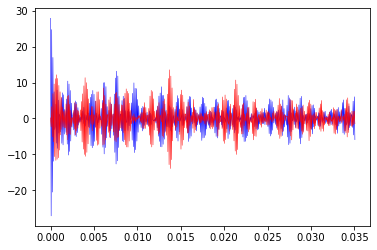

In [4]:
#pl.plot(st1.real, c = 'b', lw=0.5)
#pl.plot(st1.imag, c='r', lw=0.5)

pl.plot(t1, st1.real, c = 'b', lw=0.5)
pl.plot(t1, st1.imag, c='r', lw=0.5)


Peaks: [111.484375  112.0703125 115.3515625 115.9375    116.2890625 117.2265625
 117.4609375 118.046875 ]
Linewidths (Hz):  [0.37530872 0.35313845 0.37013326 0.35030358 0.41618407 0.28599038
 0.39705204 0.40297714]
Input LW1 values (Hz):  [0.20855299 0.12554896 0.38525298 0.49815778 0.83165181 0.79066657
 0.64078063 0.87977548]


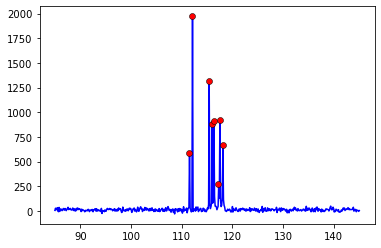

In [5]:
from scipy.signal import peak_widths

Sk1 = np.fft.fft(st1)
Sk1ZF = np.fft.fft(st1ZF)

freq1 = np.linspace(LL_Hz,HL_Hz,N1)
ppm1 = freq1 / MHz1

#freq1_ZF = np.linspace(LL_Hz,HL_Hz,N1 + len(ZF))
#ppm1_ZF = freq1_ZF / MHz1

def normalize(intensities):
    return(intensities / np.max(intensities, axis=0))

def points_to_ppm(points, FIDRES):
    ppm = points * FIDRES / (2 * MHz1) + LL_ppm
    return(ppm)

Sk1_scaled = normalize(Sk1.real)*100
max_ppm = np.argmax(Sk1_scaled)
peaks1, _= find_peaks(Sk1_scaled, height = 10)
peaks_ppm = points_to_ppm(peaks1, FIDRES1)

pl.plot(ppm1, Sk1.real, c='b', zorder = 1)
pl.scatter(peaks_ppm, Sk1[peaks1].real, c='r', edgecolor = 'k', lw = 0.5, zorder = 2)
print("Peaks:", peaks_ppm)

def peakwidth(spectrum, spectrum_peaks, fwhh):
    linewidths = np.zeros(len(spectrum_peaks))
    for p in range(len(spectrum_peaks)):
        linewidths[p] = peak_widths(spectrum, spectrum_peaks[p], rel_height=fwhh)[0][0]
    return(linewidths)

print("Linewidths (Hz): ", peakwidth(Sk1.real, peaks1[:,None], 0.5) * 2 * FIDRES1 * np.pi/N1)
print("Input LW1 values (Hz): ", LW1)

In [6]:
MHz2 = 1200.55 # Proton

# Acquisition Parameters
# Spectral Window
SW2_ppm = 20
SW2_Hz = SW2_ppm*MHz2    #
# Carrier Setting
oHp_ppm = 3.5
oHp_Hz = oHp_ppm*MHz2    #

LL_ppm2 = oHp_ppm - SW2_ppm/2 #
HL_ppm2 = oHp_ppm + SW2_ppm/2 #
LL_Hz2 = LL_ppm2*MHz2
HL_Hz2 = HL_ppm2*MHz2

# Number of points and Acquisition time
N2 = 512
Delta_T2 = 1/(2*SW2_Hz)
T2 = N2*Delta_T2
FIDRES2 = 1/T2

# Relaxation Times
LW2 = np.random.uniform(low=0.1, high=1, size=(8,))  # Hz
R2 = np.pi * LW2 / N2

# Resonances (where peaks will appear)
F2_ppm = np.array([9.65, 8.22, 9.97,7.83, 8.72, 7.98, 9.21, 8.90])
F2_Hz = F2_ppm * MHz2

# In terms of harmonics (pts)
F2_pts = (F2_Hz - LL_Hz2) * (N2/SW2_Hz)
omega2 = 2 * np.pi * F2_pts#_int

# Normalized Intensities 
S2 = np.random.uniform(low=1.0, high=5.0, size=(8,))

# Sampled points (uniform sampling)

np2 = np.arange(0,N2)
np2_ZF = np.arange(0,2*N2)
t2 = np.linspace(0.0,T2,N2)

# Sampling matrix (resonances)
omega2E = omega2[:, None] * np2[None, :]

# Sampling matrix (relaxation)
R2E = R2[:, None] * np2[None, :]
ph = 0.3

# Uniformly Sampled FID, fully quadrature detected
st2_raw_spins = (np.exp(1j * omega2E/N2) * np.exp(-R2E) * S2[:, None])
st2_raw = st2_raw_spins.sum(0)

st2max = np.max(st2_raw.real)
st2min = np.min(st2_raw.real)
# standard deviation
FIDnoise2_real = np.random.normal(0, st2max/50,N2)
FIDnoise2_imag = np.random.normal(0,st2max/50, N2)

FIDnoise2 = FIDnoise2_real + FIDnoise2_imag*1j

st2 = st2_raw + FIDnoise2

ZF2 = np.zeros(N2)
st1ZF2 = np.append(st2,ZF2)
print(st2_raw_spins.shape)

(8, 512)


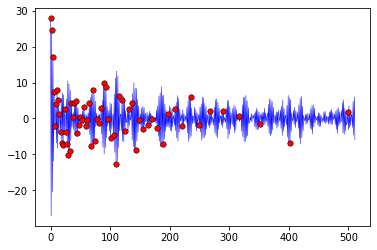

In [7]:
# Here Begins NUS!
# Start with exponentially weighted sampling

decay_rate = 0.009

num_samples = 64
num_samples = num_samples - 1
t_range = np.arange(0,N1)
t_range = t_range[:,None]
t_prob = np.exp(- decay_rate * t_range)

t_prob[0] = 0
t_prob /= t_prob.sum()
t_cdf = t_prob.cumsum()

us = (np.random.rand() + np.arange(0,num_samples)) / num_samples

ts = (us[:,None] <= t_cdf[None,:]).argmax(1)
ts = np.concatenate(([0], ts))

## Simulate noisy data
# Noise variance
#sigma = 0.77 * (1 + 0*1j)
sigma = 0.77 * (1 + 0*1j)
sigma2 = np.conjugate(sigma)*sigma

# Fill in values of sampled points
# np.random.randn(n_s) creates an n_s-sized array of random numbers, which is the length of ts array
ys = st1[ts]

# Include zero filling
y_zf = np.zeros((N1,))
#y_zf = y_zf[:,None]
t_zf = np.zeros((N1,))
#t_zf = t_zf[:,None]

ys_ZF = np.append(ys, y_zf)
#ys_ZF = ys_ZF[:,None]
ts_ZF = np.append(ts, t_zf)
#ts_ZF = ts_ZF[:,None]

## Define feature matrix (i.e. Fourier modes evaluated at each t value in ts_full)
# Total number of modes
K = N1
K_ZF = K*2
# Modes converted to array of frequencies, each corresponding to k=0, ..., N1-1
#omegas = 2 * np.pi * np.arange(0,K_ZF) / K_ZF
omegas = 2 * np.pi * np.arange(0,K) / K

# Feature matrix here is  num_samples x N1
#X = np.exp(1j*omegas[None,:] * ts_ZF[:,None]) / K_ZF
X = np.exp(1j*omegas[None,:] * ts[:,None]) / np.sqrt(len(ts)) #*len(ts)/ K
XT = np.transpose(X)
XTC = np.conjugate(XT)
# Plot selected time points
#pl.plot(np1_ZF,st1ZF.real, c = 'b', lw='0.5',zorder=1)
#pl.scatter(ts_ZF, ys_ZF.real, c = 'r', lw=0.5, s=30, edgecolor='k', zorder=2)

pl.plot(np1,st1.real, c = 'b', lw='0.5',zorder=1)
pl.scatter(ts, ys.real, c = 'r', lw=0.5, s=30, edgecolor='k', zorder=2);
#print(np.average(FIDnoise_real))
#pl.plot(t_range, t_cdf)

#XTX = np.matmul(XTC,X)
#for i in range(len(ts)):
#   print(XTX[i,i])

In [8]:
# define prior over weights (i.e. Fourier spectrum amplitudes)

chi = 100*(1 + 0*1j)
#m = np.zeros((K,)) + 1j * np.zeros((K,))
chi2 = np.conjugate(chi)*chi
#chi2 = 10000

# define Bayesian posterior mean and covariance
l = sigma2 / chi2 
#l = 0.005

Text(0.5, 0, 'Time Point')

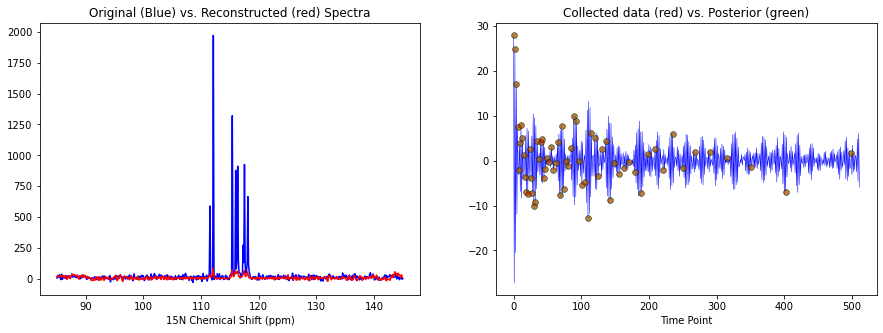

In [9]:
# feature matrix here is mapping from the frequency components to the time 
# domain data points

def update_X(freqs, t_acquired, D):
    #scaled_freqs = freqs * alpha
    N = len(t_acquired)
    Phi = np.exp(1j*freqs[None,:] * t_acquired[:,None]) / np.sqrt(N)
    # implementing relaxation time kernel
    return(Phi)

def update_X_scaled(freqs, t_acquired, D):
    N = len(t_acquired)
    Phi_scaled = np.exp(1j*alpha*freqs[None,:] * t_acquired[:,None]) / np.sqrt(N)
    # implementing relaxation time kernel
    return(Phi_scaled)

def update_m_post(Phi, reg, y):
    N, D = Phi.shape
    Phi_c = np.conjugate(Phi)
    #reg = reg / N
    
    post_var = np.linalg.inv(np.matmul(Phi_c.T, Phi) + reg * np.eye(D))
    #assert(post_var.shape == (D, D))
    post_mean = np.matmul(post_var, np.matmul(Phi_c.T, y[:,None]))
    #assert(post_mean.shape == (D, 1))
    return(post_mean)
    
def update_ys_post(Phi, mpost):
    N, D = Phi.shape
    ys_post = np.matmul(Phi, mpost)
    ys_post = ys_post[:,None]
    return(ys_post)

def rms(arr, start, end):
    sum_squares = 0
    for i in range(start, end):
        sum_squares += arr[i]**2
        
    RMS = np.sqrt(sum_squares/np.abs(end - start))
    return(RMS)

X = update_X(omegas, ts, K)    
#X_kernel = compute_fourier_rbf_kernel(ts, 10, K)
m_post_0 = update_m_post(X, l, ys)
ys_post_0 = update_ys_post(X, m_post_0)

m_post_rms = rms(m_post_0.real, 0, 128)
Sk1_rms = rms(Sk1.real, 0, 128)
scale = Sk1_rms / m_post_rms

m_post_0 = m_post_0 * scale
m_post_peaks, _ = find_peaks((m_post_0.ravel()).real, height=5)
mpp_ppm = points_to_ppm(m_post_peaks, FIDRES1)

# Plotting
k = np.arange(K)
k_ppm1 = points_to_ppm(k, FIDRES1)

fig, axs = pl.subplots(1,2,figsize=(15,5), gridspec_kw={'height_ratios': [1]})

axs[0].plot(k_ppm1, m_post_0.real, c='r',zorder = 2)
axs[0].plot(ppm1,Sk1.real, c = 'b', zorder=1)
axs[0].set_title('Original (Blue) vs. Reconstructed (red) Spectra')
axs[0].set_xlabel('15N Chemical Shift (ppm)')
#for m in mpp_ppm:
#    axs[0].axvline(m,c='g', linestyle = '--', label='fit points', alpha = 0.33)

#f = np.matmul(X, m_post_0)
axs[1].set_title('Collected data (red) vs. Posterior (green)')
axs[1].plot(np1,st1.real, c = 'b', lw='0.5',zorder=1)
axs[1].scatter(ts, ys.real, c = 'r', lw=0.5, s=30, edgecolor='k', alpha=0.5, zorder=3)
axs[1].scatter(ts, ys_post_0.real, c = 'lime', lw=0.5, edgecolor='k',alpha=0.5,zorder = 2)
axs[1].set_xlabel('Time Point')


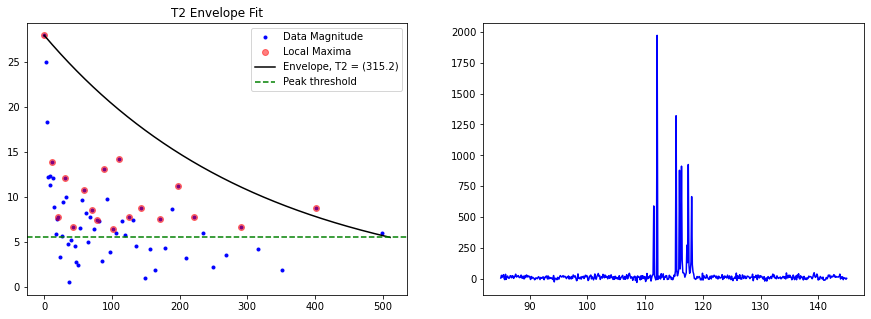

Original T2 rates: [ 781.45445645 1298.09651925  423.03283709  327.15470333  195.96501864
  206.12312186  254.3376846   185.245742  ]


In [10]:
max_amp = np.abs(ys)[0]

import warnings
def exp_decay(t, A, T2):
    # Why is this impacting the fit's weighting towards the later points?
    A = max_amp
    return(A * np.exp(-t/T2))

def find_all_maxima(signal_values, height_threshold):
    amplitudes = np.abs(signal_values)
    # Find local maxima
    peaks, _ = find_peaks(amplitudes, height=[height_threshold,np.max(amplitudes)])
    # Include absolute maximum by checking first point
    if amplitudes[0] > amplitudes[1]:
        peaks = np.concatenate(([0], peaks))
    return peaks

# Dynamic Peak Detector
def dynamic_peaks(spectrum, N_num, rms_noise, h):
    max_peaks_expected = 1.5*N_num
    spec_peaks, _ = find_peaks((spectrum.ravel()).real, height=h)
    if len(spec_peaks) > max_peaks_expected:
        h = h + 3*rms_noise
    elif len(spec_peaks) < max_peaks_expected / 2:
        h = h - rms_noise
    return(spec_peaks, h)

def fit_T2_and_correlate(t_acquired, y, spectrum, ppmthresh):
    amplitudes = np.abs(y)
    tthresh = 0.2*np.max(amplitudes)   
    tpeaks = find_all_maxima(amplitudes, tthresh)

    # Fit exponential to detected peaks
    weights = np.exp(t_acquired[tpeaks]/100) 
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        popt, _ = curve_fit(exp_decay, t_acquired[tpeaks], amplitudes[tpeaks], p0=[np.max(amplitudes),50], 
                    sigma=1/weights)
    
    # Extracting T2 from exponential fit
    T2_est = popt[1]
    # Signal envelope
    envelope = max_amp*np.exp(-np1/T2_est)
    # ridge_freqs is the m_post calculations
    om, _ = find_peaks((spectrum.ravel()).real, height=ppmthresh)  # <-- make ppmthresh dynamic
    
    return(T2_est, envelope, om)

def plot_fit(t_acquired, y, T2_est, spectrum, ppmthresh):
    fig, axs = pl.subplots(1,2,figsize=(15,5), gridspec_kw={'height_ratios': [1]})
    amplitudes = np.abs(y)
    hthresh = 0.2*np.max(amplitudes)
    peaks = find_all_maxima(amplitudes, hthresh)
    tpeaks = t_acquired[peaks]
    amp_peaks = amplitudes[peaks]
    
    envelope = fit_T2_and_correlate(t_acquired, y, spectrum, ppmthresh)[1]
    oms = fit_T2_and_correlate(t_acquired, y, spectrum, ppmthresh)[2]
    oms_ppm = points_to_ppm(oms, FIDRES1)
    
    axs[0].plot(t_acquired, amplitudes, 'b.', label='Data Magnitude')
    axs[0].plot(tpeaks, amp_peaks, 'ro', label='Local Maxima', alpha = 0.5)
    axs[0].plot(np1, envelope, 'k-', label=f'Envelope, T2 = ({T2_est:.1f})')
    axs[0].axhline(y=hthresh, color='g', linestyle='--', label='Peak threshold')
    axs[0].set_title('T2 Envelope Fit')
    
    axs[0].legend()
    axs[1].plot(k_ppm1,Sk1.real, 'b', label='FID samples')
#    for om in oms_ppm:
#        axs[1].axvline(x=om,c='g', linestyle = '--', label='fit points', alpha = 0.33)
    pl.show()

start_thresh = 5
estimated_t2 = fit_T2_and_correlate(ts, ys, m_post_0, start_thresh)[0]
plot_fit(ts, ys, estimated_t2, m_post_0, start_thresh)

print("Original T2 rates:", 1/R1)
# Note: output of oms_ppm looks different from mpp_ppm, but when subtracting the two arrays
# the difference is 0 so they are identical

In [11]:
# List of unsampled time-points
def list_unsampled_t(t_acquired):
    unsampled = np.array([x for x in t_range if x not in t_acquired])    
    return(unsampled)

first_list = list_unsampled_t(ts)


In [12]:
'''https://gregorygundersen.com/blog/2020/09/01/gaussian-entropy/'''
# Calculating the entropy of a point

def T2_kernel(t_star, t_acquired, y, spectrum):
    ts_star = np.append(t_acquired, t_star)
    envelope = (fit_T2_and_correlate(t_acquired, y, spectrum,5)[1])[:,None]
    condensed_envelope = envelope[ts_star]
    return(condensed_envelope)

def XSXT(reg, var, t_star, t_acquired, D, y, alpha):
    N = len(t_acquired)
    if N != N1:
        ts_star = np.append(t_acquired, t_star)
        #reg = reg / len(ts_star)

        freqs = 2 * alpha * np.pi * np.arange(0,D) / D
        #freqs = 2 * np.pi * np.arange(0,D) / D
        X_star = np.exp(1j*freqs[None,:] * ts_star[:,None])/ np.sqrt(len(ts_star)) #/ D    Check this

        X_star_c = np.conjugate(X_star)
        X = np.exp(1j*freqs[None,:] * t_acquired[:,None]) / np.sqrt(len(ts_star))
        X_c = np.conjugate(X)

        S_post = var * np.linalg.inv(X_c.T @ X + reg * np.eye(D))
        cond_num_star = np.linalg.cond(S_post)
        SK = X_star @ S_post @ X_star_c.T
        return(SK)
    
def Q(reg, var, t_star, t_acquired, D, y, alpha):
    SK = XSXT(reg, var, t_star, t_acquired, D, y, alpha)
    
    N = len(t_acquired)
    vdM = (var)*np.eye(N+1)
    Sigma_predictive = SK + vdM
    
    Sigma_old = Sigma_predictive[:-1,:-1]
    cond_num_sigma = np.linalg.cond(Sigma_old)
    Sigma_u = Sigma_predictive[-1,-1]
    C = Sigma_predictive[:-1,-1]
    C = C[:,None]
        
    C_c = np.conjugate(C)
    Sigma_tilda = Sigma_u - np.matmul(C_c.T, np.matmul(np.linalg.inv(Sigma_old), C))
    # Entropy Calculation for a Multivariate Gaussian
    logabsdet = np.log(np.abs(Sigma_tilda))
    ent = 0.5 * (1 + np.log(2*np.pi)) + 0.5*logabsdet

    return(ent)    

def T2kern_entropy(reg, var, t_star, t_acquired, D, y, spectrum, alpha):
    N = len(t_acquired)
    condensed_envelope = T2_kernel(t_star, t_acquired, y, spectrum)
    SK = XSXT(reg, var, t_star, t_acquired, D, y, alpha)
    
    SK = SK @ condensed_envelope
    vdM = (var)*np.eye(N+1)
    Sigma_predictive = SK + vdM
    
    Sigma_old = Sigma_predictive[:-1,:-1]
    cond_num_sigma = np.linalg.cond(Sigma_old)
    Sigma_u = Sigma_predictive[-1,-1]
    # Issue 4 fix: same row->column cross-covariance fix as Q().
    C = Sigma_predictive[:-1,-1]
    C = C[:,None]
        
    C_c = np.conjugate(C)
    Sigma_tilda = Sigma_u - np.matmul(C_c.T, np.matmul(np.linalg.inv(Sigma_old), C))
    # Entropy Calculation for a Multivariate Gaussian
    logabsdet = np.log(np.abs(Sigma_tilda))
    ent = 0.5 * (1 + np.log(2*np.pi)) + 0.5*logabsdet
    
    return(ent)


Q_star = np.array([Q(l, sigma2, t, ts, K, ys, 0.008) for t in list_unsampled_t(ts)])
pl.scatter(list_unsampled_t(ts), Q_star, c = 'lime', lw = 0.5, edgecolor = 'k')
for i in ts:
    pl.axvline(x=i, c = 'r', linestyle = '--', lw = '0.5', alpha = 0.66)

In [13]:
t_bloc = 16  

def find_max_ent(entropy_array, t_old, nt_bloc):
    unsampled = list_unsampled_t(t_old)
    # (n,1) vs. (n,)
    unsampled = unsampled[:,0]
    entropy_array = entropy_array[:,0]
    Q_star_dict = {}
    for a in range(len(unsampled)):
        Q_star_dict[unsampled[a]] = entropy_array[a]
    
    res = dict(sorted(Q_star_dict.items(), key=operator.itemgetter(1), reverse=True)[:nt_bloc])
    ts_update = np.sort(list(res.keys()))
    ts_update = np.unique(ts_update)
    return(ts_update)

#t_opt = find_max_ent(Q_star, ts, t_bloc)

sigma_new = sigma * np.random.randn(len(t_opt))
ys_new = st1[t_opt] + sigma_new

pl.plot(np1,st1.real, c = 'b', lw='0.5',zorder=1)
pl.scatter(ts, ys.real, c = 'r', lw=0.5, s=30, edgecolor='k', zorder=2)
pl.scatter(t_opt, ys_new.real, c = 'lime', lw=0.5, s=30, edgecolor='k', zorder=3)


In [14]:
def update_ts(t_old, t_new):
    t_full = np.sort(np.append(t_old, t_new))
    #t_full = np.append(t_old, t_new)
    return(t_full)

def update_ys(ys_old, t_old, t_new):
    t_full = np.append(t_old, t_new)
    #t_full = update_ts(t_old, t_new)
    
    #ys_updated = st1[t_full] + sigma * np.random.randn(len(t_full))
    sigma_var = 0.002 * (1 + 0*1j)
    ys_new = st1[t_new] + sigma_var * np.random.randn(len(t_new))
    ys_updated = np.append(ys_old, ys_new)
    
    t_ind = np.argsort(t_full)
    t_full = t_full[t_ind]
    ys_updated = ys_updated[t_ind]
    
    return(ys_updated)

Iteration number: 1
Number of sampled points: 64
Number of unsampled points: 448
Feature matrix size: (64, 512)


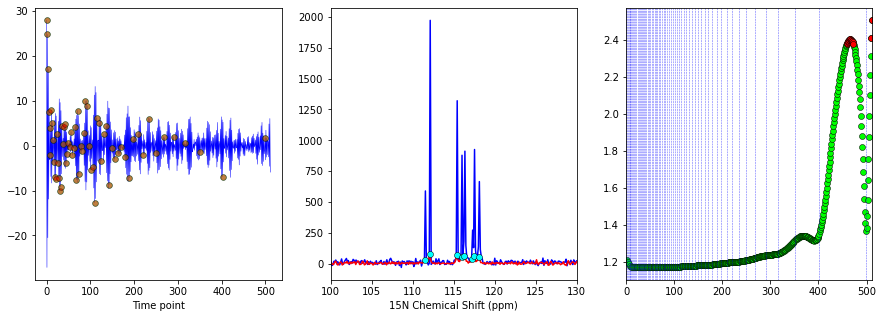

Iteration number: 2
Number of sampled points: 80
Number of unsampled points: 432
Feature matrix size: (80, 512)


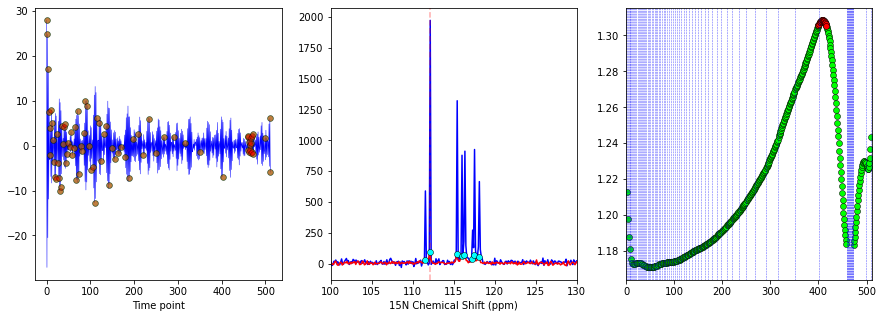

Iteration number: 3
Number of sampled points: 96
Number of unsampled points: 416
Feature matrix size: (96, 512)


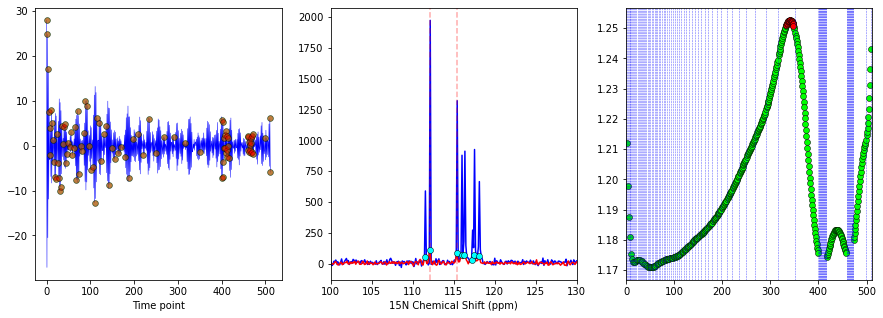

Iteration number: 4
Number of sampled points: 112
Number of unsampled points: 400
Feature matrix size: (112, 512)


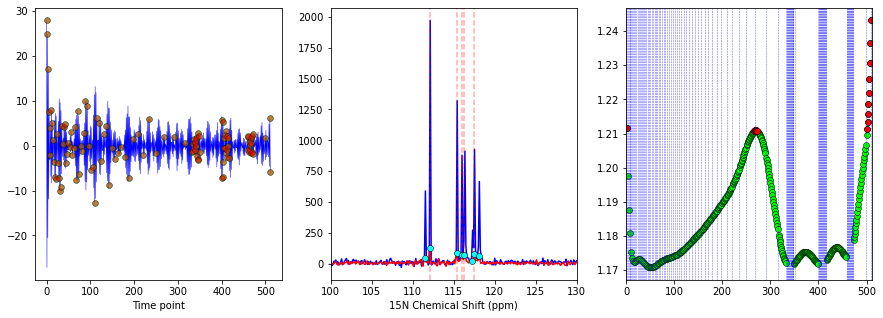

Iteration number: 5
Number of sampled points: 128
Number of unsampled points: 384
Feature matrix size: (128, 512)


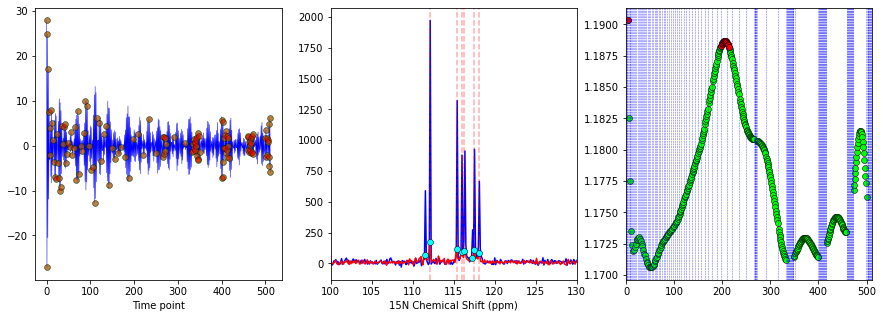

Iteration number: 6
Number of sampled points: 144
Number of unsampled points: 368
Feature matrix size: (144, 512)


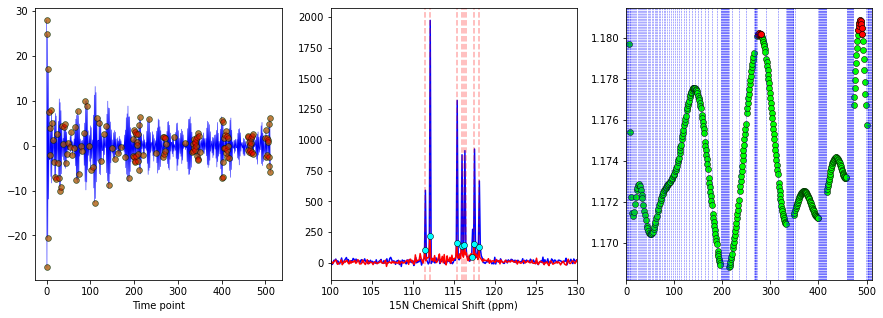

Iteration number: 7
Number of sampled points: 160
Number of unsampled points: 352
Feature matrix size: (160, 512)


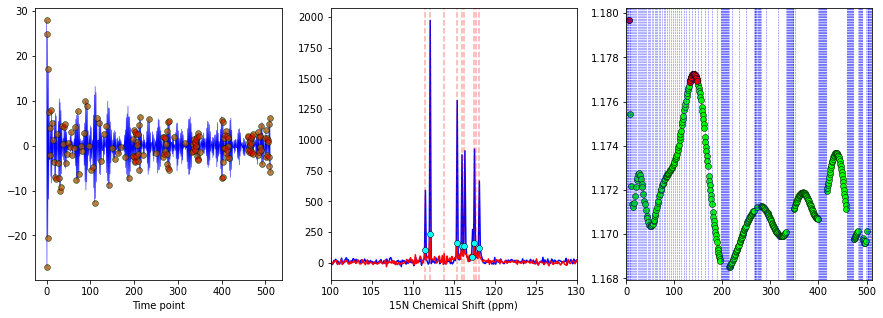

Iteration number: 8
Number of sampled points: 176
Number of unsampled points: 336
Feature matrix size: (176, 512)


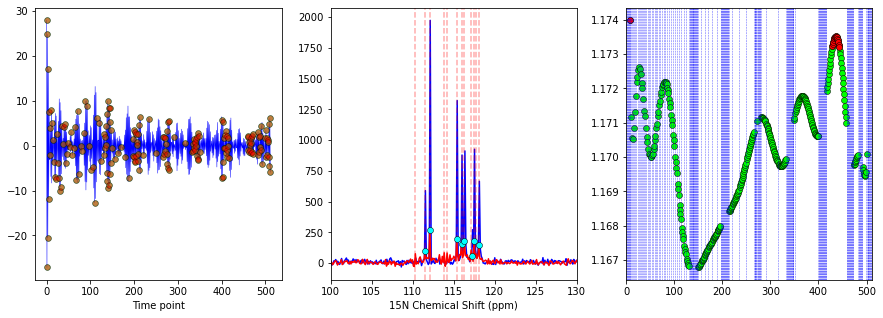

Iteration number: 9
Number of sampled points: 192
Number of unsampled points: 320
Feature matrix size: (192, 512)


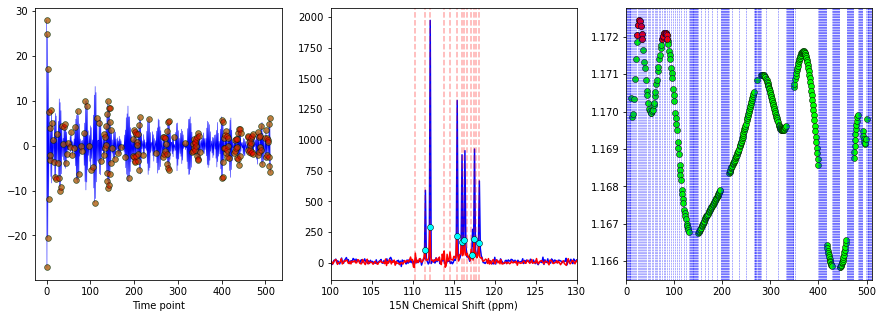

Iteration number: 10
Number of sampled points: 208
Number of unsampled points: 304
Feature matrix size: (208, 512)


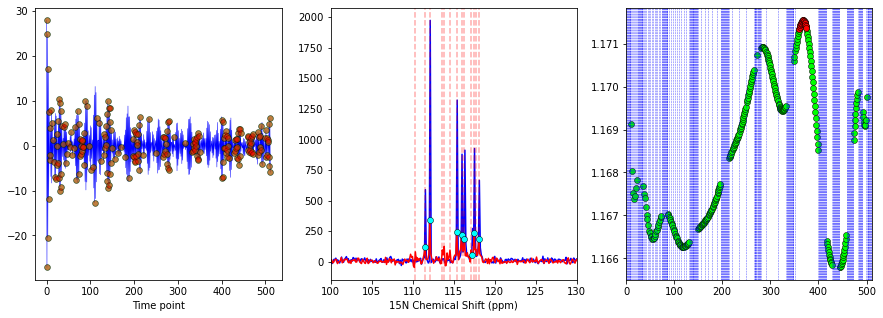

Iteration number: 11
Number of sampled points: 224
Number of unsampled points: 288
Feature matrix size: (224, 512)


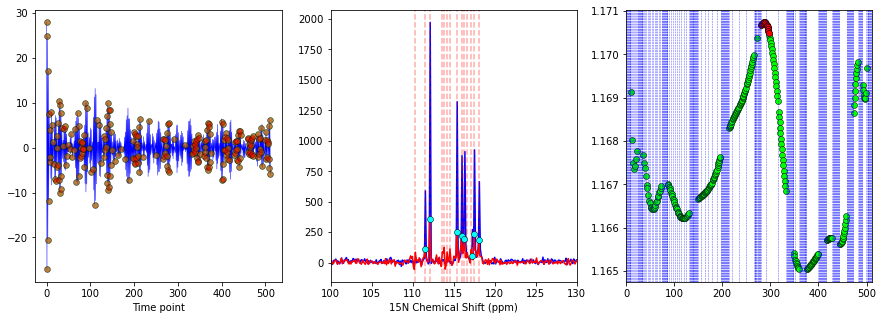

Iteration number: 12
Number of sampled points: 240
Number of unsampled points: 272
Feature matrix size: (240, 512)


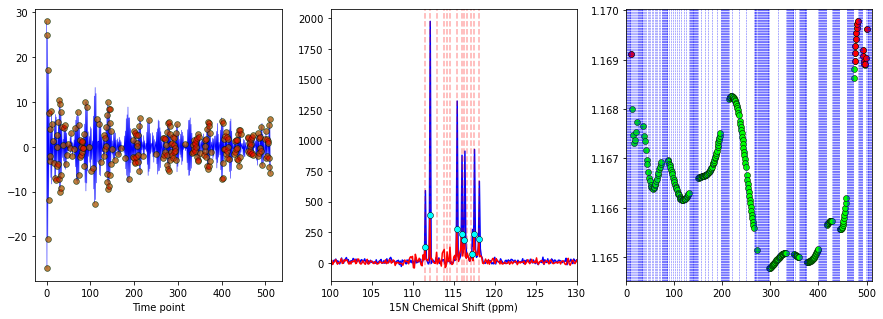

Iteration number: 13
Number of sampled points: 256
Number of unsampled points: 256
Feature matrix size: (256, 512)


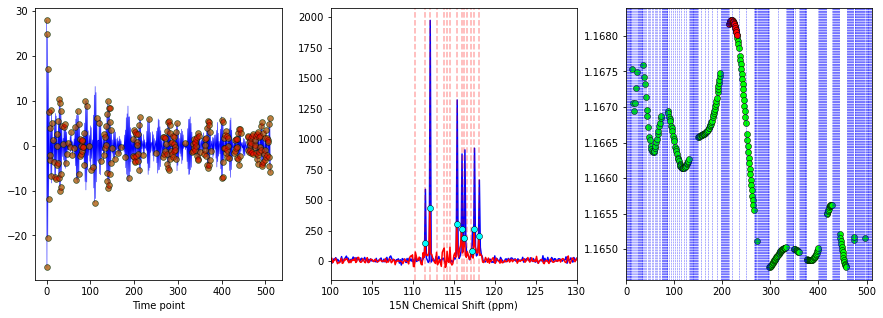

Iteration number: 14
Number of sampled points: 272
Number of unsampled points: 240
Feature matrix size: (272, 512)


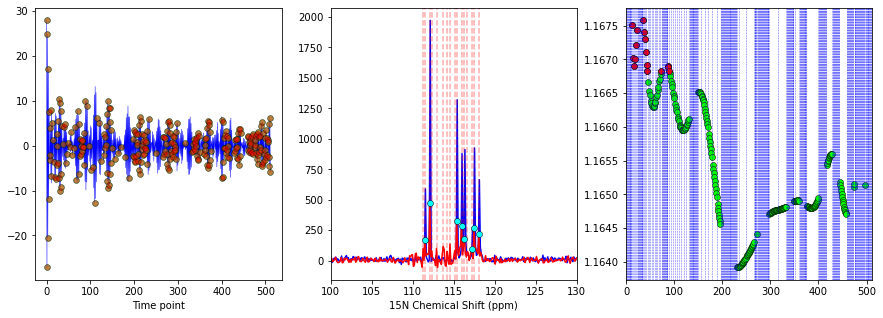

Iteration number: 15
Number of sampled points: 288
Number of unsampled points: 224
Feature matrix size: (288, 512)


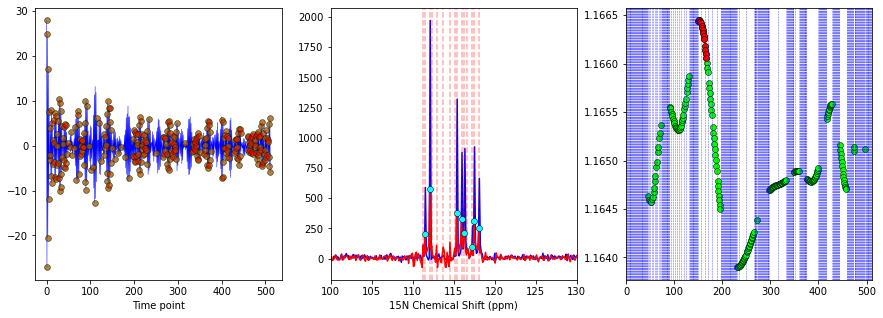

Iteration number: 16
Number of sampled points: 304
Number of unsampled points: 208
Feature matrix size: (304, 512)


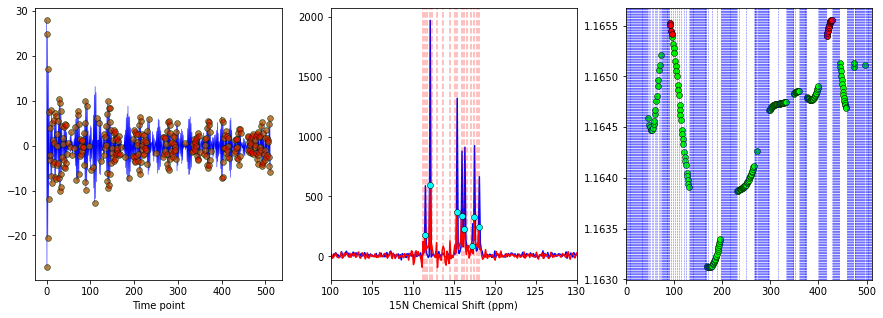

Iteration number: 17
Number of sampled points: 320
Number of unsampled points: 192
Feature matrix size: (320, 512)


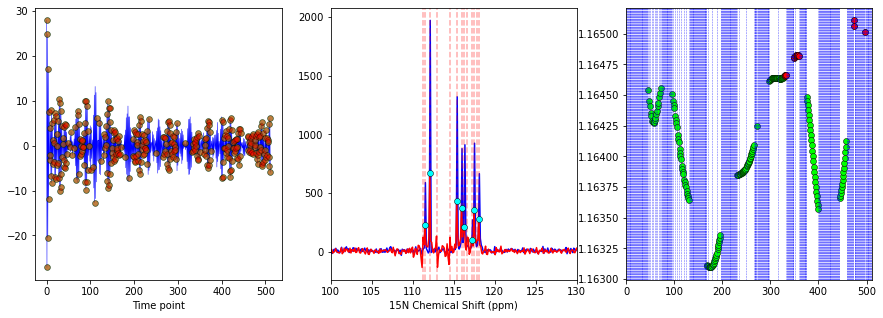

Iteration number: 18
Number of sampled points: 336
Number of unsampled points: 176
Feature matrix size: (336, 512)


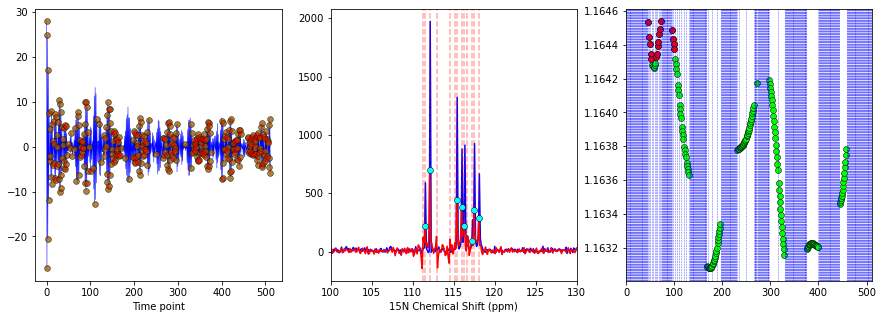

Iteration number: 19
Number of sampled points: 352
Number of unsampled points: 160
Feature matrix size: (352, 512)


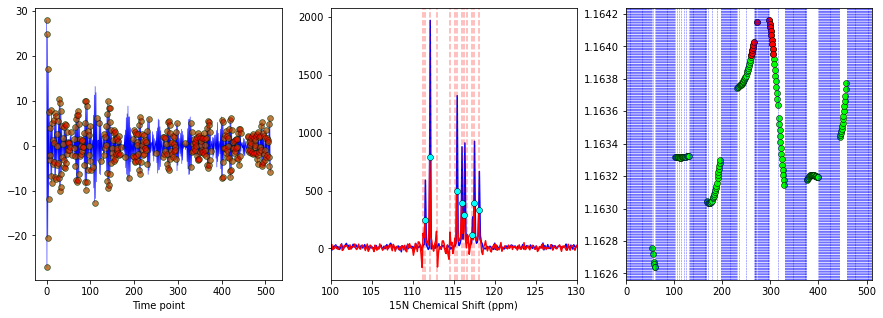

Iteration number: 20
Number of sampled points: 368
Number of unsampled points: 144
Feature matrix size: (368, 512)


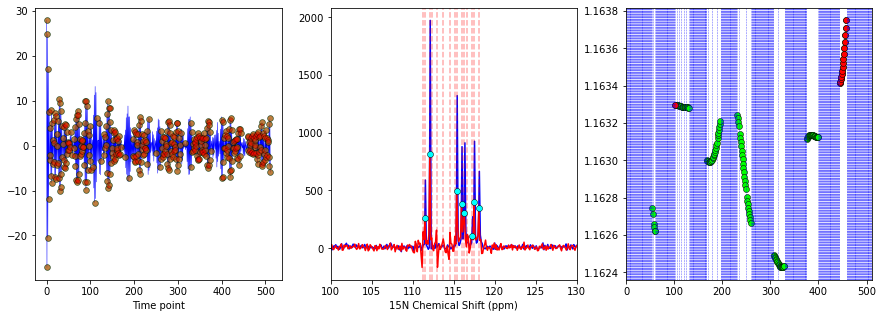

Iteration number: 21
Number of sampled points: 384
Number of unsampled points: 128
Feature matrix size: (384, 512)


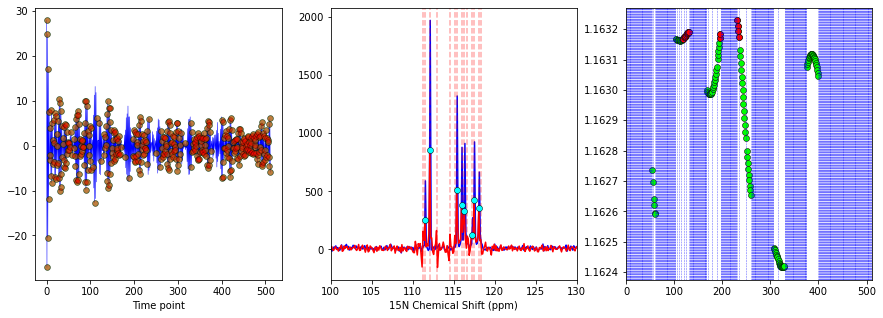

Iteration number: 22
Number of sampled points: 400
Number of unsampled points: 112
Feature matrix size: (400, 512)


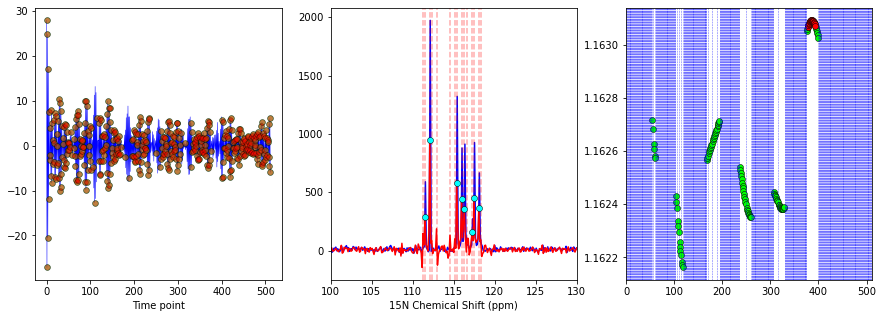

Iteration number: 23
Number of sampled points: 416
Number of unsampled points: 96
Feature matrix size: (416, 512)


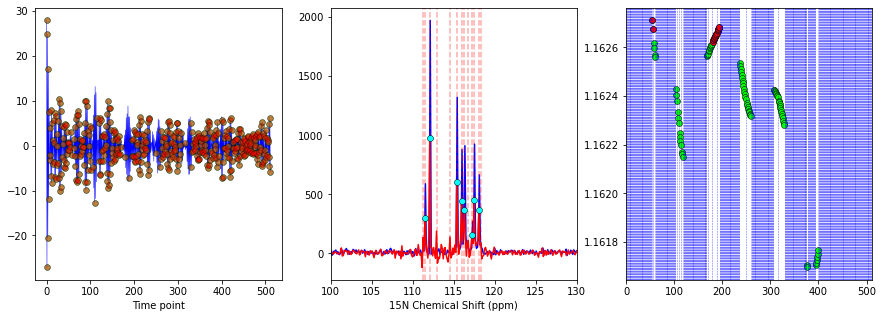

Iteration number: 24
Number of sampled points: 432
Number of unsampled points: 80
Feature matrix size: (432, 512)


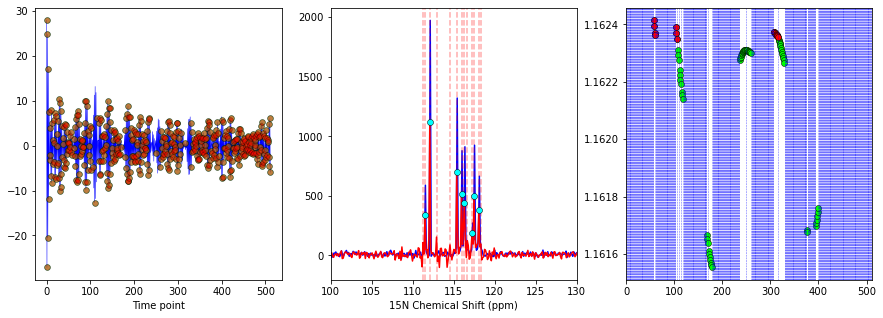

Iteration number: 25
Number of sampled points: 448
Number of unsampled points: 64
Feature matrix size: (448, 512)


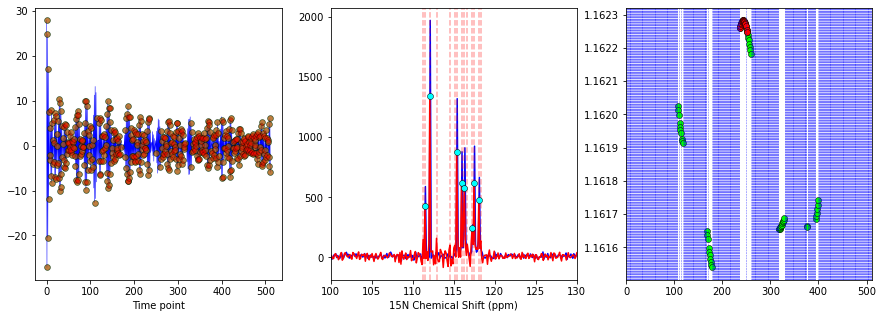

Iteration number: 26
Number of sampled points: 464
Number of unsampled points: 48
Feature matrix size: (464, 512)


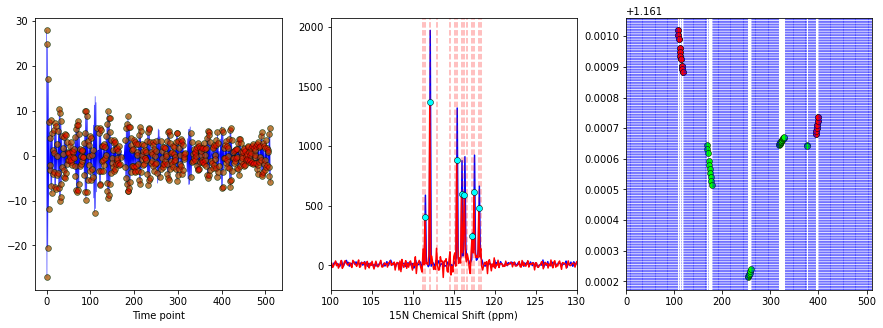

Iteration number: 27
Number of sampled points: 480
Number of unsampled points: 32
Feature matrix size: (480, 512)


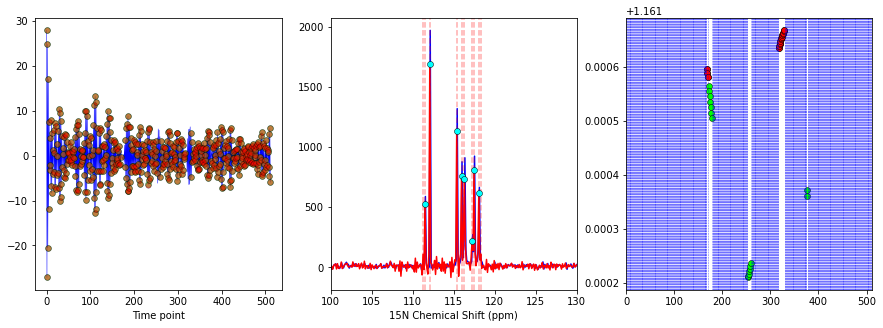

Iteration number: 28
Number of sampled points: 496
Number of unsampled points: 16
Feature matrix size: (496, 512)


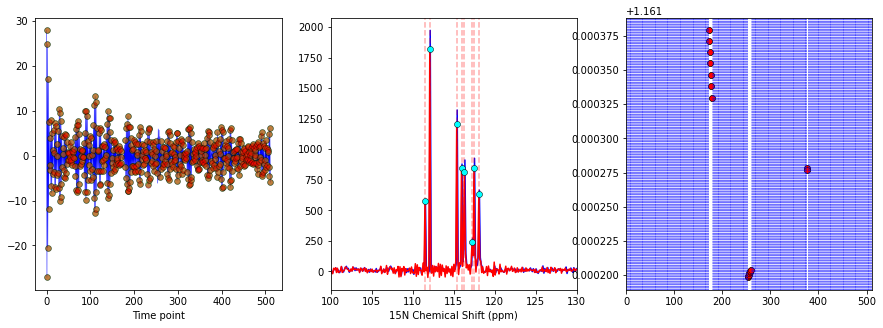

Iteration number: 29
Number of sampled points: 512
Number of unsampled points: 0
Feature matrix size: (512, 512)


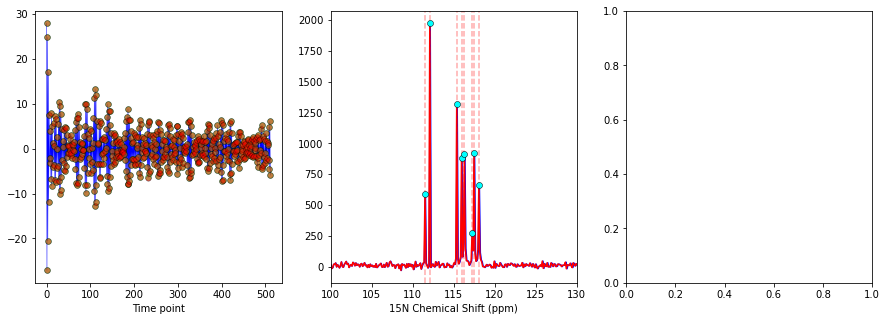

In [15]:
num_iters = int((N1 - len(ts)) / t_bloc) + 1
t_sampled = ts
ys_sampled = ys
# m_post_max = np.zeros(num_iters + 1)
m_post_maxima = np.zeros((num_iters, len(peaks1)))
signal_to_noise = np.zeros((num_iters, len(peaks1)))
Sk1_rms = rms(Sk1.real, 0, 128)

T2_array = np.zeros(num_iters)
pthresh = 5

for i in range(0, num_iters):
    t_unsampled = list_unsampled_t(t_sampled)
    X = update_X(omegas, t_sampled, K) #* len(t_sampled) / K # * len(t_range)/len(t_sampled) #
    m_post = update_m_post(X, l, ys_sampled)
    ys_post = update_ys_post(X,m_post)
        
    noise_update = rms(m_post.real, 0, 128)
    scale = Sk1_rms / (noise_update)
    
    m_post_scaled = m_post * scale
    
    for j in range(len(peaks1)):
        m_post_maxima[i,j] = m_post_scaled.real[peaks1[j]].item()
        signal_to_noise[i,j] = m_post_maxima[i,j] / noise_update.item()
    
    T2_estimate = fit_T2_and_correlate(t_sampled, ys_sampled, m_post, pthresh)[0]
    envelope_estimate = fit_T2_and_correlate(t_sampled, ys_sampled, m_post, pthresh)[1]
    omsest = fit_T2_and_correlate(t_sampled, ys_sampled, m_post, pthresh)[2]
    omsest_ppm = points_to_ppm(omsest, FIDRES1)
    
    T2_array[i] = T2_estimate
    
    # Figure plotting    
    fig, axs = pl.subplots(1,3, figsize=(15,5), gridspec_kw={'height_ratios': [1]})
    
    axs[0].plot(np1,st1.real, c = 'b', lw='0.5',zorder=1)
    axs[0].scatter(t_sampled, ys_post.real, c = 'lime', lw=0.5, edgecolor='k',alpha=0.5, zorder = 2)
    axs[0].scatter(t_sampled, ys_sampled.real, c = 'r', lw=0.5, s=30, edgecolor='k', alpha=0.5, zorder=3)
    #axs[0].plot(np1, envelope_estimate, 'k-', label=f'Envelope, T2 = ({T2_estimate:.1f})')
    axs[0].set_xlabel("Time point")
    
    
    axs[1].plot(ppm1,Sk1.real, c = 'b', zorder=1)
    axs[1].plot(k_ppm1, m_post_scaled.real, c='r', zorder=2)
    
    axs[1].scatter(peaks_ppm, m_post_maxima[i,:], c = 'cyan', edgecolor = 'k', lw = 0.5, zorder = 3)
    axs[1].set_xlabel("15N Chemical Shift (ppm)")
    axs[1].set_xlim(100,130)
    for omest in omsest_ppm:
        axs[1].axvline(x=omest,c='r', linestyle = '--', alpha = 0.33)
    
    print("Iteration number:", i+1)
    print("Number of sampled points:", t_sampled.shape[0])
    print("Number of unsampled points:", t_unsampled.shape[0])
    print("Feature matrix size:", X.shape)
    #print("Estimated T2:", T2_estimate)
    # print(T2_array)
    #print("S/N of Tallest Peak: %0.2f" % np.max(signal_to_noise[i,:]))
    #print("S/N of Tallest Peak in Reference Signal: %0.2f" % np.max(Sk1.real / Sk1_rms))
        
    # Plot Entropy
    if t_unsampled.shape[0] > 0:
        #tstar_ent = calculate_entropy(l, sigma2, t_unsampled, t_sampled, K, ys_sampled, m_post, 0.008) 
        Q_star = np.array([Q(l, sigma2, t, t_sampled, K, ys_sampled, 0.008) for t in t_unsampled])
        # Update parameters
        #t_opt = find_max_ent(tstar_ent, t_sampled, t_bloc)
        t_opt = find_max_ent(Q_star, t_sampled, t_bloc)
        t_opt_indices = np.array([np.where(t_unsampled == t)[0][0] for t in t_opt])
        Q_opt = Q_star[t_opt_indices]
        #Q_opt = tstar_ent[t_opt_indices]
        #pthresh = dynamic_peaks(m_post, 8, Sk1_rms, pthresh)
        axs[2].scatter(t_unsampled, Q_star, c = 'lime', lw = 0.5, edgecolor = 'k')
        axs[2].scatter(t_opt, Q_opt, c = 'r', lw = 0.5, edgecolor = 'k')
        axs[2].set_xlim(0,N1)
        #axs[2].set_ylim(0,2)

        for i in t_sampled:
            axs[2].axvline(x=i, c = 'b', linestyle = '--', lw = '0.5', alpha = 0.66, zorder = 1)
            #axs[2].axvline(x=i, c = 'r', linestyle = '--', lw = '0.5', alpha = 0.66, zorder = 1)
        
        ys_sampled = update_ys(ys_sampled, t_sampled, t_opt)
        t_sampled = update_ts(t_sampled, t_opt)
    pl.show()

Relaxation list: [ 781.45445645 1298.09651925  423.03283709  327.15470333  195.96501864
  206.12312186  254.3376846   185.245742  ]


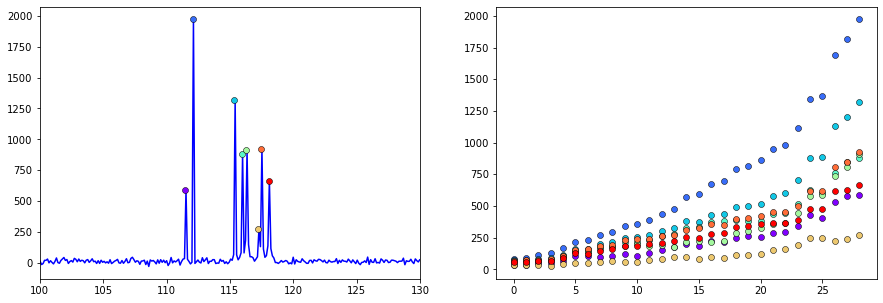

In [16]:
colors = cm.rainbow(np.linspace(0,1,len(peaks1)))
x = np.arange(num_iters)

normalized_maxima = normalize(m_post_maxima)
fig, axs = pl.subplots(1,2, figsize=(15,5), gridspec_kw={'height_ratios': [1]})
axs[0].plot(ppm1, Sk1.real, c='b', zorder = 1)

print("Relaxation list:", 1/R1)
for j, c in zip(range(len(peaks1)), colors):
    axs[0].scatter(peaks_ppm[j], Sk1.real[peaks1[j]], color=c, edgecolor = 'k', lw = 0.5, zorder = 2)
    axs[0].set_xlim(100,130)
    axs[1].scatter(x, m_post_maxima[x,j], color = c, edgecolor = 'k', lw = 0.5)
   # axs[2].scatter(x, T2_array, c='b')
  #  axs[2].scatter(x, signal_to_noise[x,j], color = c, edgecolor = 'k', lw = 0.5)
    pl.plot()

In [17]:
def random_cdf_selection(d_r, t_r, nt_bloc, t_old):
    # Convert t_old to a set for faster lookup
    sampled_points = set(t_old)
    
    # Initialize output array
    t_new = np.zeros(nt_bloc, dtype=int)
    points_selected = 0
    
    while points_selected < nt_bloc:
        # Calculate probabilities only for unsampled points
        t_likelihood = np.exp(- d_r * t_r)
        t_likelihood[list(sampled_points)] = 0
        
        # If no more points available, break
        if np.sum(t_likelihood) == 0:
            break
            
        t_likelihood /= t_likelihood.sum()
        t_cdf_r = t_likelihood.cumsum()
        
        # Select one point at a time
        u = np.random.rand()
        new_point = (u <= t_cdf_r).argmax()
        
        # Only add if not already selected
        if new_point not in sampled_points:
            t_new[points_selected] = new_point
            sampled_points.add(new_point)
            points_selected += 1
            
    return t_likelihood, t_new[:points_selected]
'''

def random_cdf_selection(d_r, t_r, nt_bloc, t_acquired):

    t_u = list_unsampled_t(t_acquired)
    
    t_likelihood = np.exp(-d_r * t_r)
    
    if len(t_u) > 0:

        t_likelihood[t_acquired] = 0
        t_likelihood /= t_likelihood.sum()

        #t_cdf_r = t_likelihood.cumsum()
        t_cdf_r = norm.cdf(t_likelihood)
        t_cdf_r = t_cdf_r.flatten()
        print(t_cdf_r.shape)

        #t_likelihood /= t_likelihood.sum()
        #t_cdf_r = t_likelihood.cumsum()

        u = (np.random.randn() + np.arange(0, nt_bloc))/nt_bloc
        print(u.shape)
        t_new = (u[:,None] <= t_cdf_r[None,:]).argmax(1)

        for t in t_new:
            if t in t_acquired:
                np.delete(t_new, t)

        return(t_new)
'''
    
    

'\n\ndef random_cdf_selection(d_r, t_r, nt_bloc, t_acquired):\n\n    t_u = list_unsampled_t(t_acquired)\n    \n    t_likelihood = np.exp(-d_r * t_r)\n    \n    if len(t_u) > 0:\n\n        t_likelihood[t_acquired] = 0\n        t_likelihood /= t_likelihood.sum()\n\n        #t_cdf_r = t_likelihood.cumsum()\n        t_cdf_r = norm.cdf(t_likelihood)\n        t_cdf_r = t_cdf_r.flatten()\n        print(t_cdf_r.shape)\n\n        #t_likelihood /= t_likelihood.sum()\n        #t_cdf_r = t_likelihood.cumsum()\n\n        u = (np.random.randn() + np.arange(0, nt_bloc))/nt_bloc\n        print(u.shape)\n        t_new = (u[:,None] <= t_cdf_r[None,:]).argmax(1)\n\n        for t in t_new:\n            if t in t_acquired:\n                np.delete(t_new, t)\n\n        return(t_new)\n'

Iteration number: 1
Number of sampled points: 64
Number of unsampled points: 448
Feature matrix size: (64, 512)
S/N of Tallest Peak: 91.07
S/N of Tallest Peak in Reference Signal: 125.01


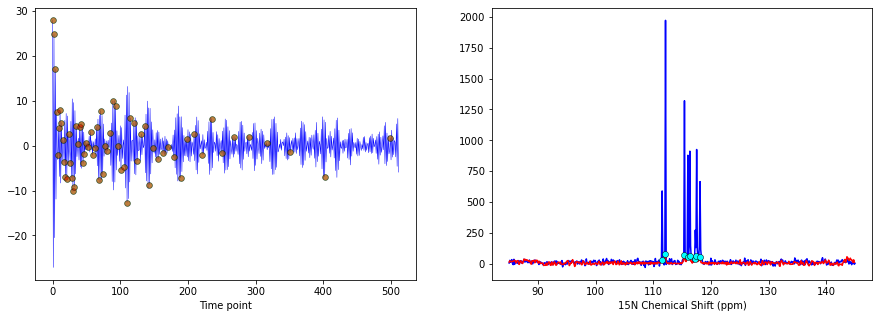

Iteration number: 2
Number of sampled points: 80
Number of unsampled points: 432
Feature matrix size: (80, 512)
S/N of Tallest Peak: 107.17
S/N of Tallest Peak in Reference Signal: 125.01


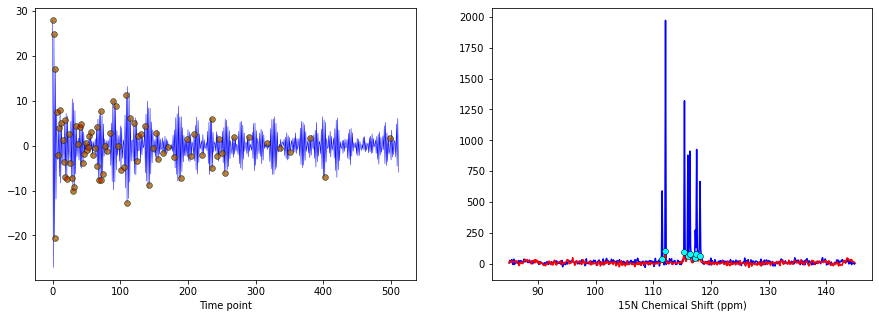

Iteration number: 3
Number of sampled points: 96
Number of unsampled points: 416
Feature matrix size: (96, 512)
S/N of Tallest Peak: 106.49
S/N of Tallest Peak in Reference Signal: 125.01


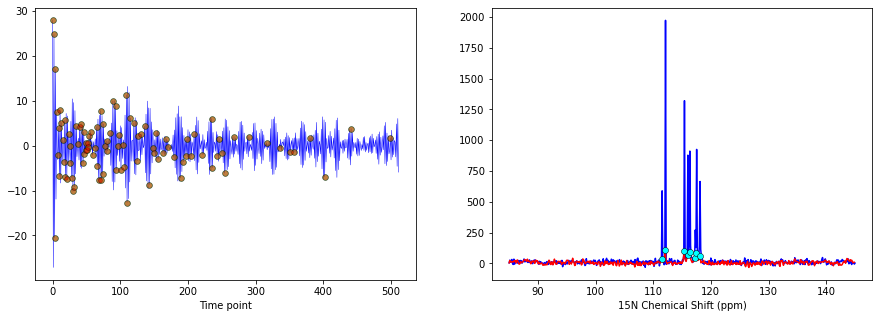

Iteration number: 4
Number of sampled points: 112
Number of unsampled points: 400
Feature matrix size: (112, 512)
S/N of Tallest Peak: 164.21
S/N of Tallest Peak in Reference Signal: 125.01


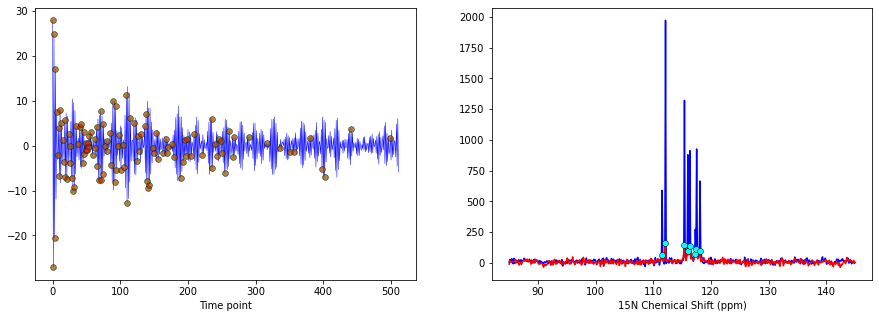

Iteration number: 5
Number of sampled points: 128
Number of unsampled points: 384
Feature matrix size: (128, 512)
S/N of Tallest Peak: 156.91
S/N of Tallest Peak in Reference Signal: 125.01


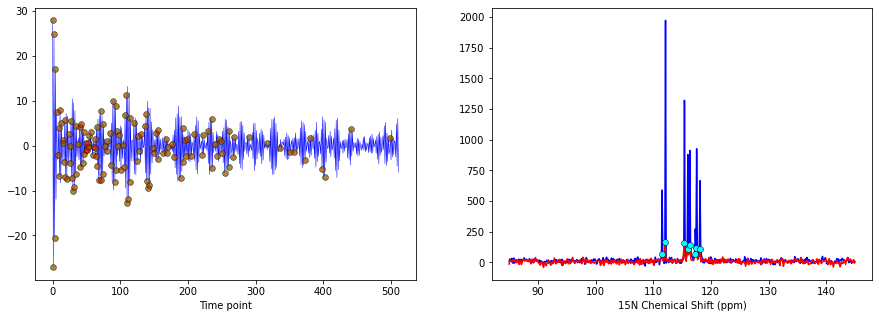

Iteration number: 6
Number of sampled points: 144
Number of unsampled points: 368
Feature matrix size: (144, 512)
S/N of Tallest Peak: 172.67
S/N of Tallest Peak in Reference Signal: 125.01


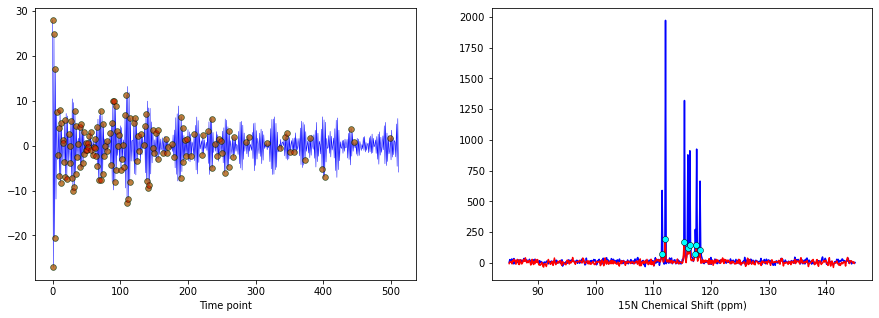

Iteration number: 7
Number of sampled points: 160
Number of unsampled points: 352
Feature matrix size: (160, 512)
S/N of Tallest Peak: 209.28
S/N of Tallest Peak in Reference Signal: 125.01


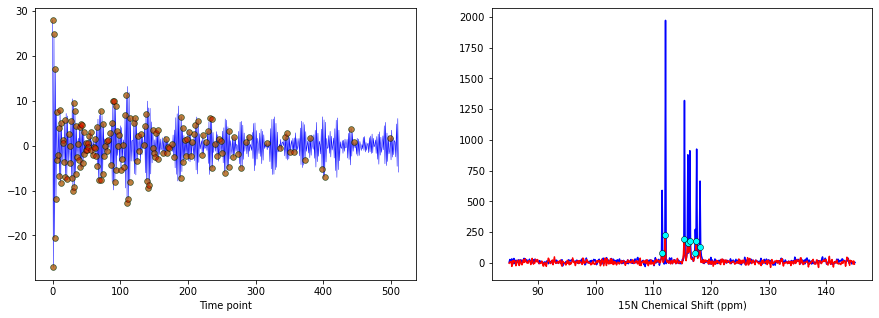

Iteration number: 8
Number of sampled points: 176
Number of unsampled points: 336
Feature matrix size: (176, 512)
S/N of Tallest Peak: 241.85
S/N of Tallest Peak in Reference Signal: 125.01


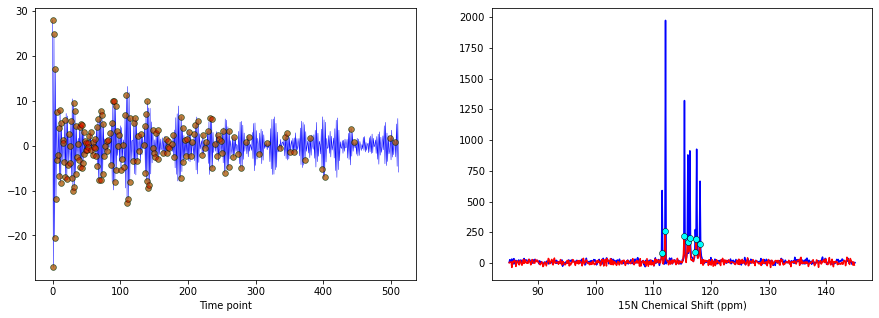

Iteration number: 9
Number of sampled points: 192
Number of unsampled points: 320
Feature matrix size: (192, 512)
S/N of Tallest Peak: 252.44
S/N of Tallest Peak in Reference Signal: 125.01


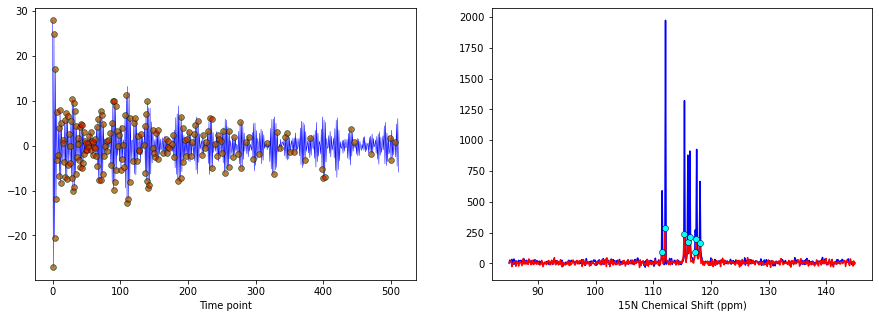

Iteration number: 10
Number of sampled points: 208
Number of unsampled points: 304
Feature matrix size: (208, 512)
S/N of Tallest Peak: 287.01
S/N of Tallest Peak in Reference Signal: 125.01


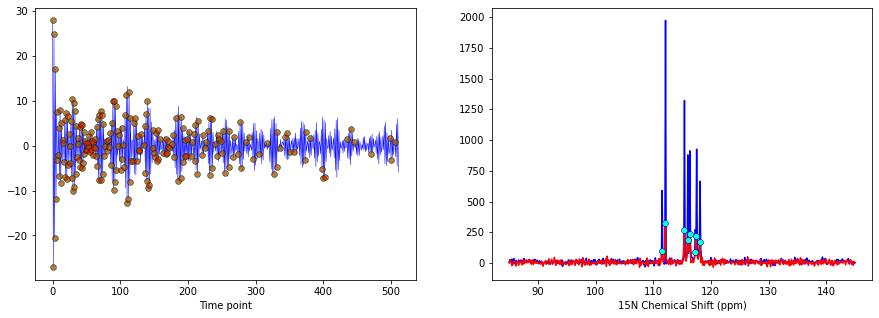

Iteration number: 11
Number of sampled points: 224
Number of unsampled points: 288
Feature matrix size: (224, 512)
S/N of Tallest Peak: 350.12
S/N of Tallest Peak in Reference Signal: 125.01


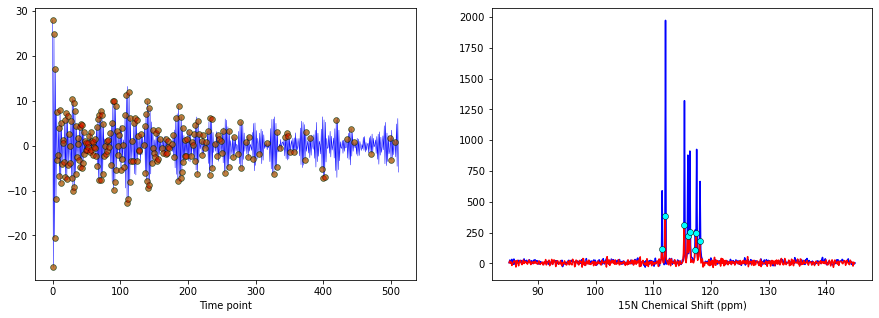

Iteration number: 12
Number of sampled points: 240
Number of unsampled points: 272
Feature matrix size: (240, 512)
S/N of Tallest Peak: 354.26
S/N of Tallest Peak in Reference Signal: 125.01


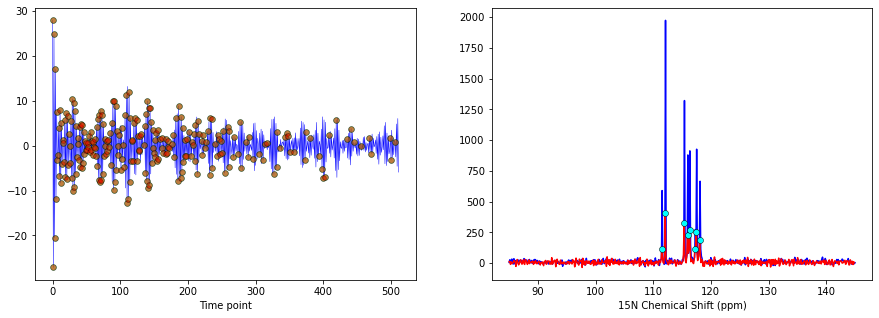

Iteration number: 13
Number of sampled points: 256
Number of unsampled points: 256
Feature matrix size: (256, 512)
S/N of Tallest Peak: 411.61
S/N of Tallest Peak in Reference Signal: 125.01


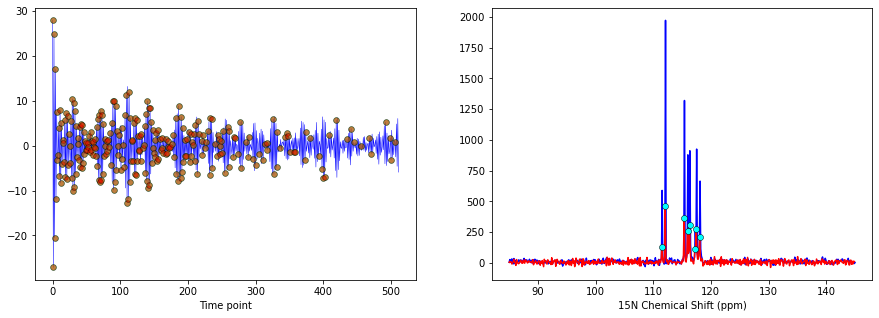

Iteration number: 14
Number of sampled points: 272
Number of unsampled points: 240
Feature matrix size: (272, 512)
S/N of Tallest Peak: 475.40
S/N of Tallest Peak in Reference Signal: 125.01


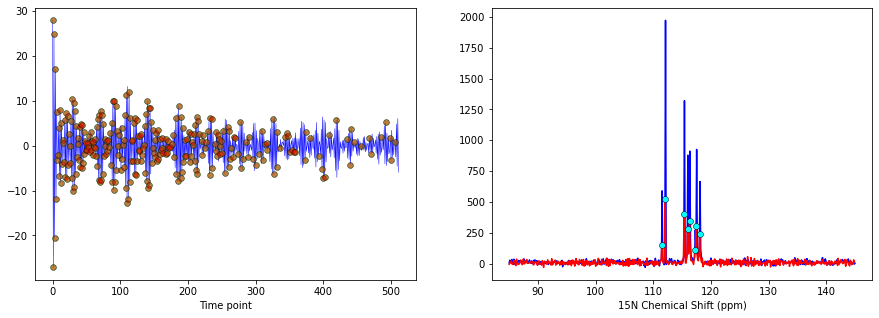

Iteration number: 15
Number of sampled points: 288
Number of unsampled points: 224
Feature matrix size: (288, 512)
S/N of Tallest Peak: 443.47
S/N of Tallest Peak in Reference Signal: 125.01


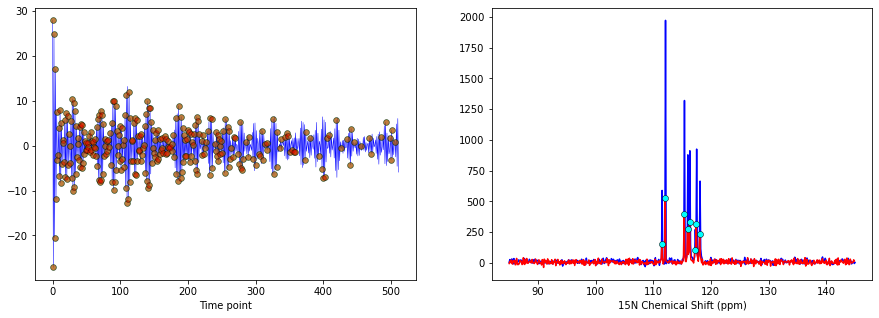

Iteration number: 16
Number of sampled points: 304
Number of unsampled points: 208
Feature matrix size: (304, 512)
S/N of Tallest Peak: 450.15
S/N of Tallest Peak in Reference Signal: 125.01


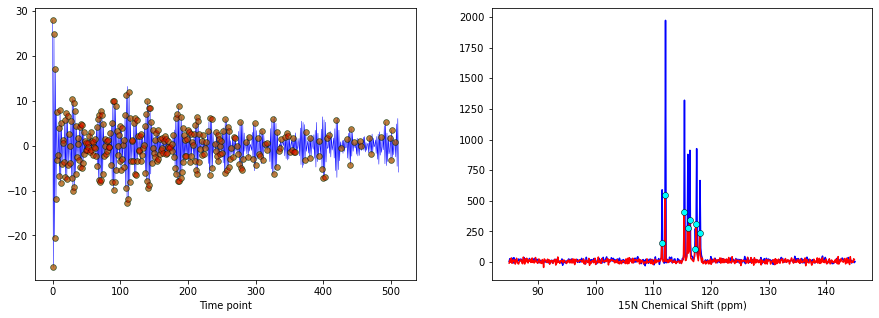

Iteration number: 17
Number of sampled points: 320
Number of unsampled points: 192
Feature matrix size: (320, 512)
S/N of Tallest Peak: 509.81
S/N of Tallest Peak in Reference Signal: 125.01


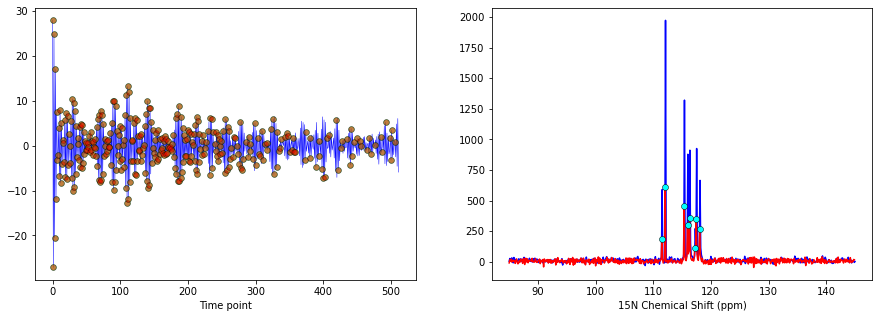

Iteration number: 18
Number of sampled points: 336
Number of unsampled points: 176
Feature matrix size: (336, 512)
S/N of Tallest Peak: 527.88
S/N of Tallest Peak in Reference Signal: 125.01


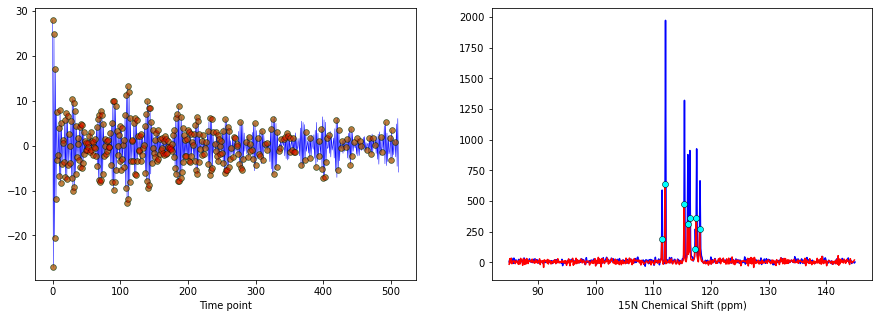

Iteration number: 19
Number of sampled points: 352
Number of unsampled points: 160
Feature matrix size: (352, 512)
S/N of Tallest Peak: 621.97
S/N of Tallest Peak in Reference Signal: 125.01


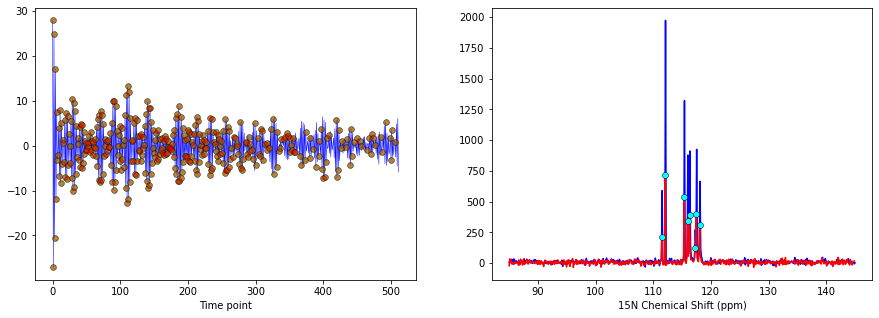

Iteration number: 20
Number of sampled points: 368
Number of unsampled points: 144
Feature matrix size: (368, 512)
S/N of Tallest Peak: 620.78
S/N of Tallest Peak in Reference Signal: 125.01


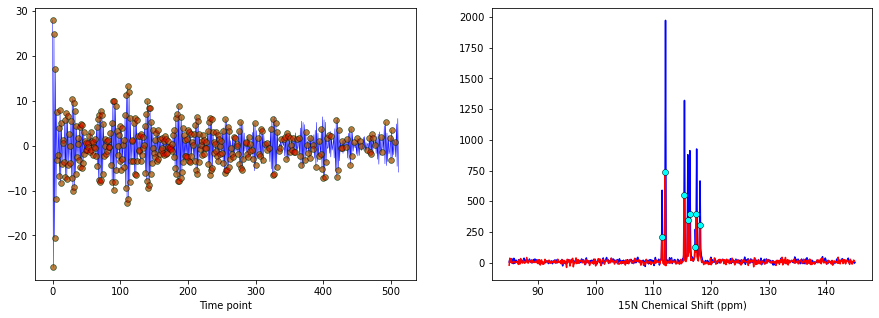

Iteration number: 21
Number of sampled points: 384
Number of unsampled points: 128
Feature matrix size: (384, 512)
S/N of Tallest Peak: 775.75
S/N of Tallest Peak in Reference Signal: 125.01


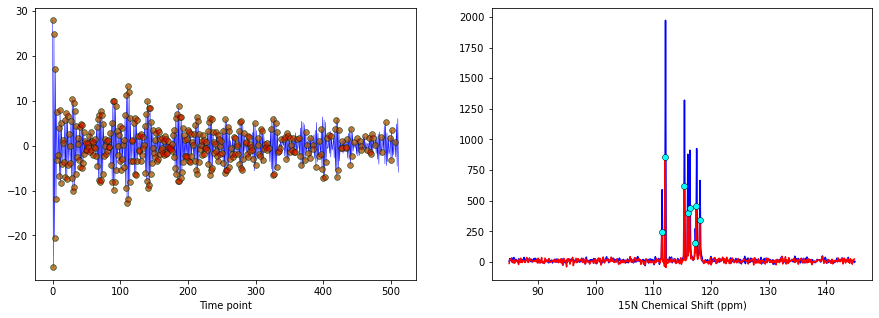

Iteration number: 22
Number of sampled points: 400
Number of unsampled points: 112
Feature matrix size: (400, 512)
S/N of Tallest Peak: 850.58
S/N of Tallest Peak in Reference Signal: 125.01


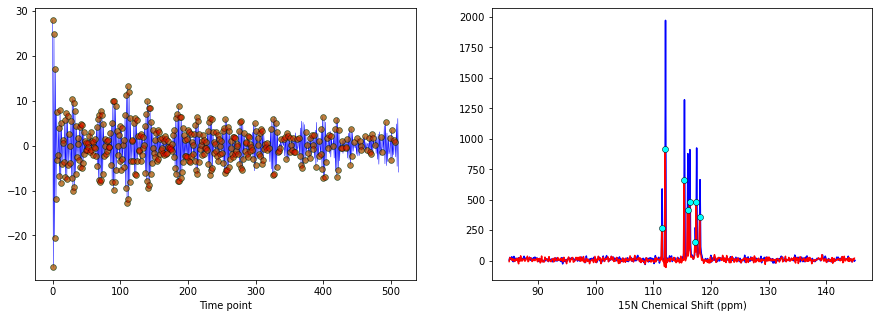

Iteration number: 23
Number of sampled points: 416
Number of unsampled points: 96
Feature matrix size: (416, 512)
S/N of Tallest Peak: 951.31
S/N of Tallest Peak in Reference Signal: 125.01


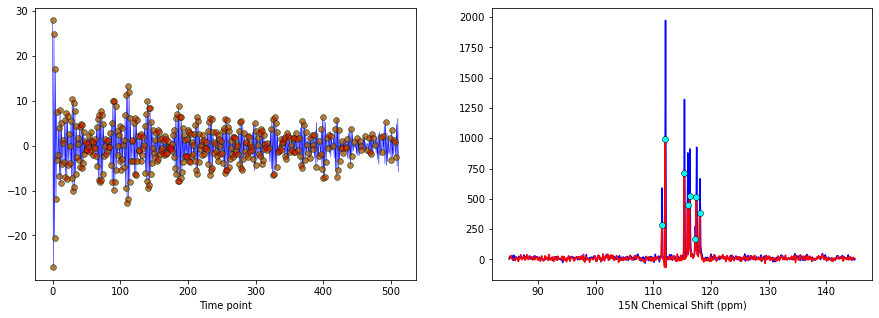

Iteration number: 24
Number of sampled points: 432
Number of unsampled points: 80
Feature matrix size: (432, 512)
S/N of Tallest Peak: 957.61
S/N of Tallest Peak in Reference Signal: 125.01


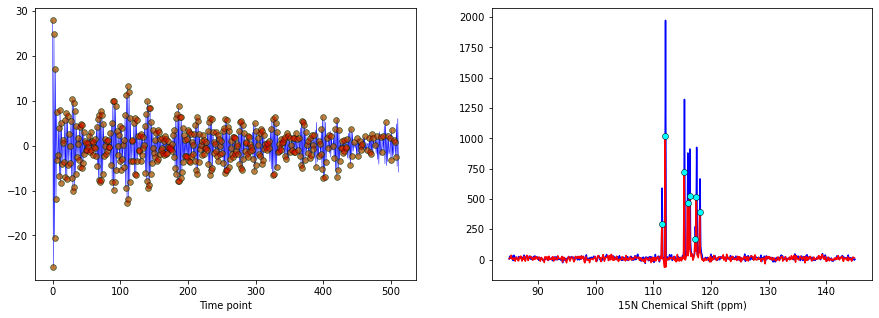

Iteration number: 25
Number of sampled points: 448
Number of unsampled points: 64
Feature matrix size: (448, 512)
S/N of Tallest Peak: 1035.44
S/N of Tallest Peak in Reference Signal: 125.01


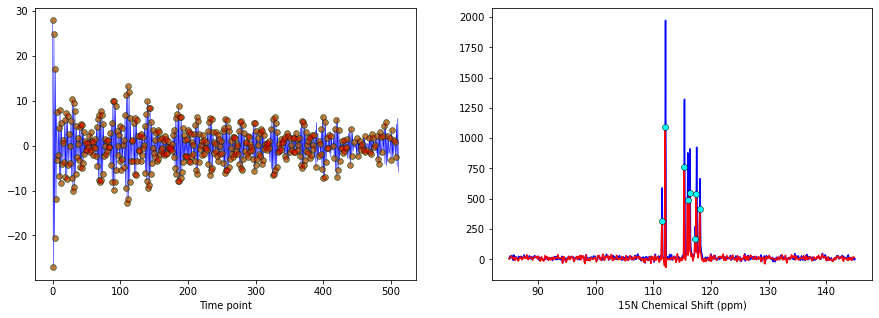

Iteration number: 26
Number of sampled points: 464
Number of unsampled points: 48
Feature matrix size: (464, 512)
S/N of Tallest Peak: 1108.04
S/N of Tallest Peak in Reference Signal: 125.01


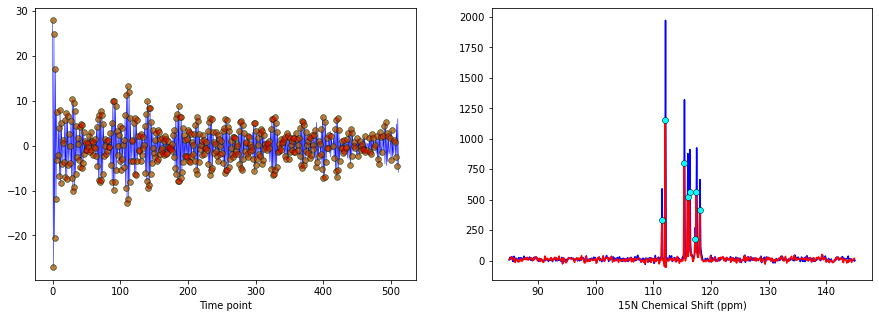

Iteration number: 27
Number of sampled points: 480
Number of unsampled points: 32
Feature matrix size: (480, 512)
S/N of Tallest Peak: 1319.10
S/N of Tallest Peak in Reference Signal: 125.01


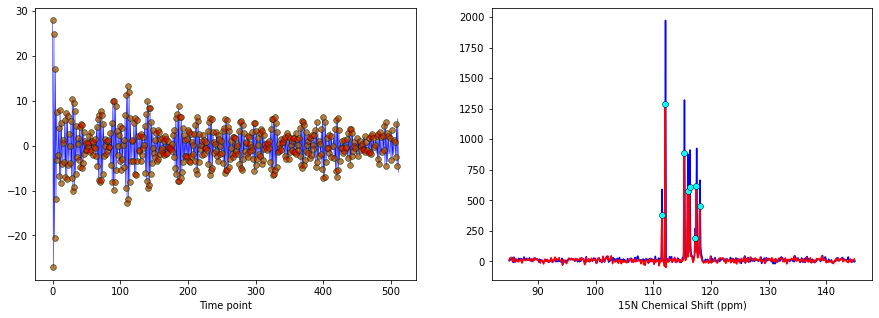

Iteration number: 28
Number of sampled points: 496
Number of unsampled points: 16
Feature matrix size: (496, 512)
S/N of Tallest Peak: 1439.21
S/N of Tallest Peak in Reference Signal: 125.01


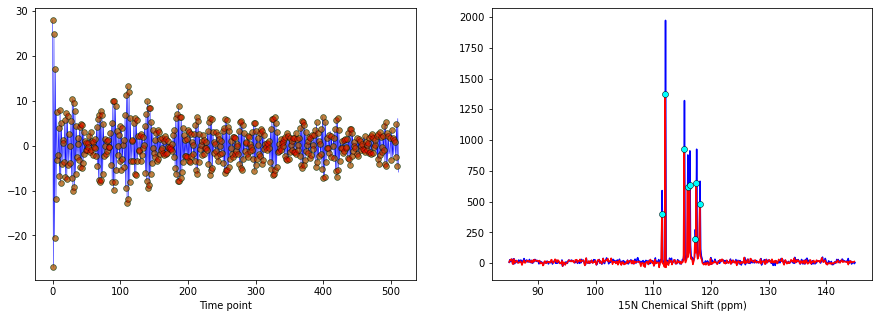

Iteration number: 29
Number of sampled points: 512
Number of unsampled points: 0
Feature matrix size: (512, 512)
S/N of Tallest Peak: 2828.76
S/N of Tallest Peak in Reference Signal: 125.01


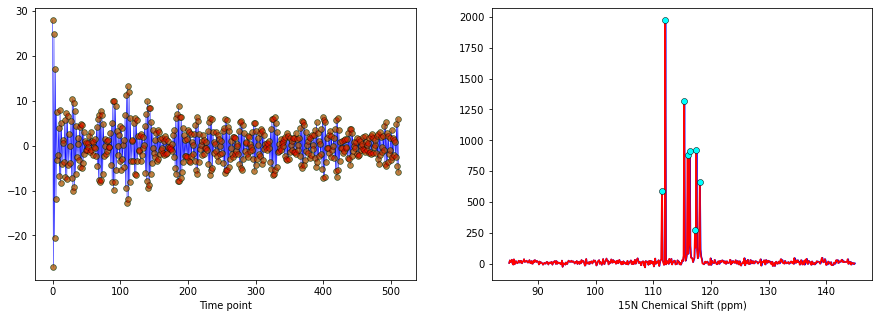

In [18]:
# Random sampling
num_iters = int((N1 - len(ts)) / t_bloc) + 1
t_prob = np.exp(- decay_rate * t_range)
t_prob /= t_prob.sum()
t_cdf = t_prob.cumsum()

t_r_sampled = ts

ys_r_sampled = ys
m_post_r_maxima = np.zeros((num_iters, len(peaks1)))
signal_to_noise_r = np.zeros((num_iters, len(peaks1)))

for i in range(0, num_iters):

    t_r_unsampled = list_unsampled_t(t_r_sampled)
    X_r = update_X(omegas, t_r_sampled, K) #* len(t_r_sampled) / K #* len(t_range)/len(t_r_sampled) #
    m_r_post = update_m_post(X_r, l, ys_r_sampled) 
    ys_r_post = update_ys_post(X_r, m_r_post)
    
    noise_update_r = rms(m_r_post.real, 0, 128)
    scale_r = Sk1_rms / noise_update_r
    
    m_r_post_scaled = m_r_post * scale_r
    
    for j in range(len(peaks1)):
        m_post_r_maxima[i,j] = m_r_post_scaled.real[peaks1[j]].item() #* scale_r
        signal_to_noise_r[i,j] = m_post_r_maxima[i,j] / noise_update_r.item()
        
        
    # Figure printing
    fig, axs = pl.subplots(1,2, figsize=(15,5), gridspec_kw={'height_ratios': [1]})
    
    axs[0].plot(np1,st1.real, c = 'b', lw='0.5',zorder=1)
    axs[0].scatter(t_r_sampled, ys_r_post.real, c = 'lime', lw=0.5, edgecolor='k',alpha=0.5, zorder = 2)
    axs[0].scatter(t_r_sampled, ys_r_sampled.real, c = 'r', lw=0.5, s=30, edgecolor='k', alpha=0.5, zorder=3)
    axs[0].set_xlabel("Time point")
    
    axs[1].plot(ppm1,Sk1.real, c = 'b', zorder=1)
    axs[1].plot(k_ppm1, m_r_post_scaled.real, c='r', zorder=2)
    axs[1].scatter(peaks_ppm, m_post_r_maxima[i,:], c = 'cyan', edgecolor = 'k', lw = 0.5, zorder = 3)
    axs[1].set_xlabel("15N Chemical Shift (ppm)")
    
    print("Iteration number:", i+1)    
    print("Number of sampled points:", t_r_sampled.shape[0])
    print("Number of unsampled points:", t_r_unsampled.shape[0])
    print("Feature matrix size:", X_r.shape)
    print("S/N of Tallest Peak: %0.2f" % np.max(signal_to_noise_r[i,:]))
    print("S/N of Tallest Peak in Reference Signal: %0.2f" % np.max(Sk1.real / Sk1_rms))

    if t_r_unsampled.shape[0] > 0:
        # Update parameters
        t_prob = random_cdf_selection(decay_rate, t_range, t_bloc, t_r_sampled)[0]
        tr_opt = random_cdf_selection(decay_rate, t_range, t_bloc, t_r_sampled)[1]
        #print(tr_opt)
        ys_r_sampled = update_ys(ys_r_sampled, t_r_sampled, tr_opt)
        t_r_sampled = update_ts(t_r_sampled, tr_opt)
   
    pl.show()
    

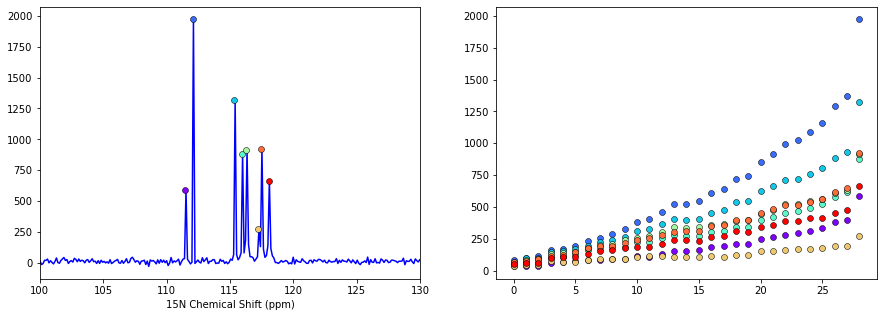

In [19]:
normalized_maxima_r = normalize(m_post_r_maxima)
fig, axs = pl.subplots(1,2, figsize=(15,5), gridspec_kw={'height_ratios': [1]})
axs[0].plot(ppm1, Sk1.real, c='b', zorder = 1)
axs[0].set_xlabel("15N Chemical Shift (ppm)")

for j, c in zip(range(len(peaks1)), colors):
    axs[0].scatter(peaks_ppm[j], Sk1.real[peaks1[j]], color=c, edgecolor = 'k', lw = 0.5, zorder = 2)
    axs[0].set_xlim(100,130)
    axs[1].scatter(x,  m_post_r_maxima[x,j], color = c, edgecolor = 'k', lw = 0.5)
   #axs[2].scatter(x, signal_to_noise_r[x,j], color = c, edgecolor = 'k', lw = 0.5)
    pl.plot()

    

fig, axs = pl.subplots(1,2, figsize=(15,5), gridspec_kw={'height_ratios': [1]})

for j, c in zip(range(len(peaks)), colors):
    axs[0].scatter(x,  m_post_maxima[x,j] / x, color = c, edgecolor = 'k', lw = 0.5)
    axs[0].set_title('Active Sampling')
    axs[1].scatter(x,  m_post_r_maxima[x,j] / x, color = c, edgecolor = 'k', lw = 0.5)
    axs[1].set_title('Random Exponentially Weighted Sampling')
    pl.plot()

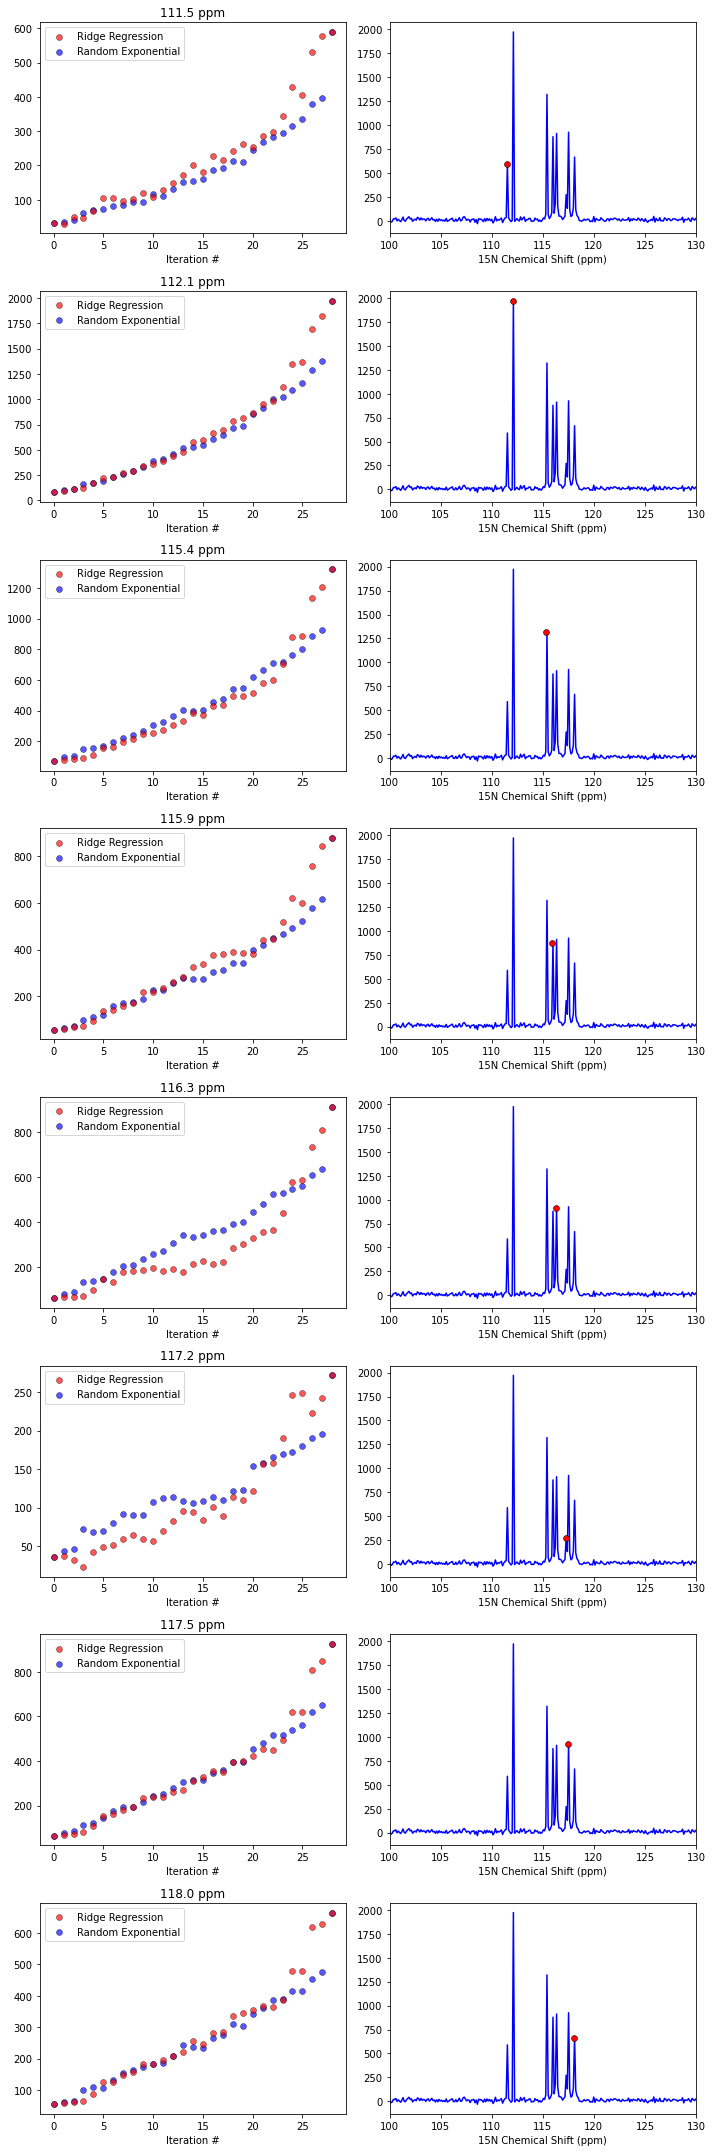

In [20]:
fig, axs = pl.subplots(len(peaks1), 2, figsize=(10,30))

for j in range(len(peaks1)):
    axs[j,0].scatter(x,  m_post_maxima[x,j], c = 'r', edgecolor = 'k', alpha = 0.66, lw = 0.5, zorder = 2)
    axs[j,0].scatter(x,  m_post_r_maxima[x,j], c = 'b', edgecolor = 'k', alpha = 0.66, lw = 0.5, zorder = 1)
    axs[j,0].set_title("%1.1f ppm" %peaks_ppm[j])
    axs[j,0].set_xlabel("Iteration #")
    axs[j,0].legend(['Ridge Regression', 'Random Exponential'])
    
    axs[j,1].plot(ppm1, Sk1.real, c='b', zorder = 1)
    axs[j,1].scatter(peaks_ppm[j], Sk1.real[peaks1[j]], c = 'r', edgecolor = 'k', lw = 0.5, zorder = 2)
    axs[j,1].set_xlim(100,130)
    axs[j,1].set_xlabel("15N Chemical Shift (ppm)")
    
    #axs[j,2].plot(k_ppm, m_post.real)
    fig.tight_layout()
    pl.plot()
    

'''[111.484375  112.0703125 115.3515625 115.9375    116.2890625 117.2265625
 117.4609375 118.046875 ]'''

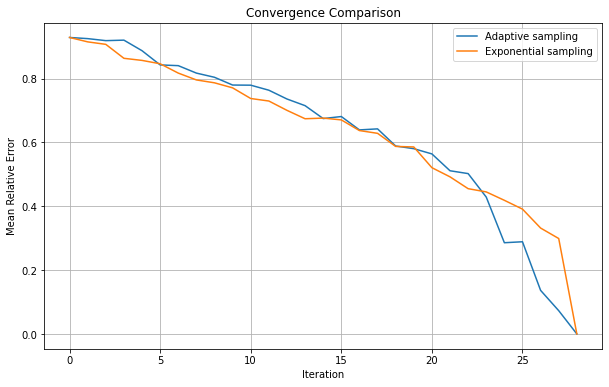

(array([9.28835473e-01, 9.25209188e-01, 9.18889810e-01, 9.20442283e-01,
        8.87345776e-01, 8.42840978e-01, 8.40547349e-01, 8.17231498e-01,
        8.04097929e-01, 7.79786539e-01, 7.79362262e-01, 7.63607824e-01,
        7.36072889e-01, 7.15231654e-01, 6.74783112e-01, 6.81167514e-01,
        6.39268151e-01, 6.42512669e-01, 5.88796125e-01, 5.80470127e-01,
        5.64071800e-01, 5.11298790e-01, 5.02396421e-01, 4.28823501e-01,
        2.85869362e-01, 2.88890723e-01, 1.36605669e-01, 7.30208032e-02,
        1.91944882e-04]),
 array([9.28835473e-01, 9.15046259e-01, 9.07271674e-01, 8.63549225e-01,
        8.56969118e-01, 8.46460699e-01, 8.17231062e-01, 7.95812663e-01,
        7.86765944e-01, 7.70995530e-01, 7.37621110e-01, 7.29755504e-01,
        7.00545241e-01, 6.74211832e-01, 6.76259446e-01, 6.70627301e-01,
        6.37197681e-01, 6.28564915e-01, 5.87546108e-01, 5.85859161e-01,
        5.20923232e-01, 4.92211825e-01, 4.55177817e-01, 4.45024985e-01,
        4.18718294e-01, 3.91138952e-01

In [21]:
# Compare both methods
def compare_convergence(adaptive_intensities, exponential_intensities, true_values):
    # intensities: (n_timepoints, n_peaks)
    # true_values: (n_peaks,)
    true_values = true_values[None,:]
    # Calculate relative errors for all timepoints
    adaptive_error = np.abs(adaptive_intensities - true_values) / true_values
    exponential_error = np.abs(exponential_intensities - true_values) / true_values
    
    # Mean error across peaks (axis=1 to average over peaks)
    mean_adaptive = np.mean(adaptive_error, axis=1)
    mean_exponential = np.mean(exponential_error, axis=1)
    
    # Plot comparison
    pl.figure(figsize=(10,6))
    pl.plot(range(len(mean_adaptive)), mean_adaptive, label='Adaptive sampling')
    pl.plot(range(len(mean_exponential)), mean_exponential, label='Exponential sampling')
    pl.xlabel('Iteration')
    pl.ylabel('Mean Relative Error')
    pl.legend()
    pl.grid(True)
    pl.title('Convergence Comparison')
    pl.show()
    
    return(mean_adaptive, mean_exponential)

compare_convergence(m_post_maxima, m_post_r_maxima, Sk1.real[peaks1])

In [22]:
# Moving into using Kernels
'''st1_raw = (np.exp(1j * omega1E/N1) * np.exp(-R1E) * S1[:, None]).sum(0)'''

def signal_kernel(t1, t2, freqs = None, amps = None, R2 = None):
    nmr = 0
    for f, a in zip(frequencies, amplitudes):
        # We can use a kernel based directly off of our model of a complex
        # NMR signal because it so happens to have conjugate symmetry
        nmr += a * np.exp(-np.abs(t1-t2)*R2) * np.exp(1j*f*(t1-t2))
        
    return(nmr)

